# Machine Learning Cybersecurity Project

## Lab 3: Tree Ensembles

This notebook extends the fixed Lab 2 pipeline with bagged trees, random forests, gradient boosting, and XGBoost. It preserves the same cleaned observations, stable row identifiers, train-validation-test assignments, and training-only preprocessing decisions.

## Task 1 - Restore the fixed evaluation protocol

**Objective.** Locate the CICIDS2017 files and load the row assignments saved in Lab 2. Verify the random seed, split sizes, stable row identifiers, and software versions before fitting any model. This ensures that every Lab 3 model is evaluated on exactly the same observations as the Lab 2 baselines.

In [2]:
# Purpose: Restore Lab 2 saved memberships, configuration, and software-version information.
# Explain: Reusing the split makes ensemble comparisons refer to the same underlying flow population.

from pathlib import Path
from importlib.metadata import version
import json

import numpy as np
import pandas as pd

RANDOM_SEED = 42

LAB2_DIRECTORY = Path("../Lab2")
DATA_DIRECTORY = LAB2_DIRECTORY / "MachineLearningCSV"
ARTIFACT_DIRECTORY = LAB2_DIRECTORY / "artifacts"

SPLIT_PATH = ARTIFACT_DIRECTORY / "fixed_split_assignments.csv.gz"
CONFIGURATION_PATH = ARTIFACT_DIRECTORY / "fixed_split_config.json"

csv_files = sorted(DATA_DIRECTORY.rglob("*.csv"))

if not csv_files:
    raise FileNotFoundError(f"No CSV files found in {DATA_DIRECTORY}")

with CONFIGURATION_PATH.open(encoding="utf-8") as configuration_file:
    split_configuration = json.load(configuration_file)

split_assignments = pd.read_csv(
    SPLIT_PATH,
    dtype={
        "row_id": "string",
        "Label": "string",
        "binary_label": "string",
        "partition": "category",
    },
)

assert split_configuration["random_seed"] == RANDOM_SEED
assert len(split_assignments) == split_configuration["rows"]
assert split_assignments["row_id"].is_unique
assert set(split_assignments["partition"]) == {
    "train", "validation", "test"
}

split_summary = pd.crosstab(
    split_assignments["binary_label"],
    split_assignments["partition"],
).reindex(
    index=["BENIGN", "ATTACK"],
    columns=["train", "validation", "test"],
    fill_value=0,
)

software_versions = pd.Series({
    "numpy": version("numpy"),
    "scipy": version("scipy"),
    "pandas": version("pandas"),
    "scikit-learn": version("scikit-learn"),
    "xgboost": version("xgboost"),
    "matplotlib": version("matplotlib"),
    "seaborn": version("seaborn"),
}, name="version")

print(f"CSV files: {len(csv_files)}")
print(f"Rows in fixed split: {len(split_assignments):,}")
print(f"Random seed: {RANDOM_SEED}")
display(split_summary)
display(software_versions.to_frame())

CSV files: 8
Rows in fixed split: 2,522,362
Random seed: 42


partition,train,validation,test
binary_label,,,
BENIGN,1257890,419297,419297
ATTACK,255527,85175,85176


,version
numpy,2.1.3
scipy,1.15.3
pandas,2.2.3
scikit-learn,1.6.1
xgboost,2.1.1
matplotlib,3.10.0
seaborn,0.13.2


### Interpretation

The Lab 2 protocol was restored successfully: eight CICIDS2017 files are available, and the saved assignment contains 2,522,362 unique modeled flows. The training, validation, and test memberships remain fixed, so later performance differences can be attributed to the models rather than a changed data split. The recorded package versions will support the reproducibility appendix.

## Task 2 - Restore the cleaned Lab 2 observations

**Objective.** Load the original flow features and retain exactly the rows identified by Lab 2's saved assignments. Reuse the same label normalization and preserve the existing training, validation, and test memberships.


In [3]:
# Purpose: Reload reduced files and retain rows identified by the saved Lab 2 protocol.
# Explain: Align by stable row_id instead of rerunning a new random allocation or duplicate policy.

web_attack_label_map = {
    "Web Attack ï¿½ Brute Force": "Web Attack - Brute Force",
    "Web Attack ï¿½ Sql Injection": "Web Attack - Sql Injection",
    "Web Attack ï¿½ XSS": "Web Attack - XSS",
    "Web Attack � Brute Force": "Web Attack - Brute Force",
    "Web Attack � Sql Injection": "Web Attack - Sql Injection",
    "Web Attack � XSS": "Web Attack - XSS",
}

frames = []
original_rows = 0

for csv_file in csv_files:
    frame = pd.read_csv(
        csv_file, encoding="cp1252", low_memory=False
    )
    frame.columns = frame.columns.str.strip()

    frame["source_file"] = csv_file.relative_to(
        DATA_DIRECTORY
    ).as_posix()
    frame["source_row"] = np.arange(1, len(frame) + 1)
    frame["row_id"] = (
        frame["source_file"].astype("string")
        + "::"
        + frame["source_row"].astype("string")
    )

    original_rows += len(frame)
    frames.append(
        frame.loc[frame["row_id"].isin(split_assignments["row_id"])]
    )

model_df = pd.concat(frames, ignore_index=True)
del frames, frame

model_df["Label"] = (
    model_df["Label"]
    .astype("string")
    .str.strip()
    .replace(web_attack_label_map)
)

# Align features and saved labels using stable row identifiers.
saved_protocol = split_assignments.set_index("row_id")
model_df = model_df.set_index("row_id").loc[saved_protocol.index]

if not model_df["Label"].equals(saved_protocol["Label"]):
    raise ValueError("Restored labels do not match the Lab 2 assignments.")

model_df["binary_label"] = saved_protocol["binary_label"]
model_df["partition"] = saved_protocol["partition"]
model_df = model_df.reset_index()

train_mask = model_df["partition"].eq("train")
validation_mask = model_df["partition"].eq("validation")
test_mask = model_df["partition"].eq("test")

restoration_summary = pd.Series({
    "original_csv_rows": original_rows,
    "rows_excluded_by_lab2_cleaning": original_rows - len(model_df),
    "restored_modeling_rows": len(model_df),
    "training_rows": int(train_mask.sum()),
    "validation_rows": int(validation_mask.sum()),
    "test_rows": int(test_mask.sum()),
}, name="rows")

display(restoration_summary.to_frame())


,rows
original_csv_rows,2830743
rows_excluded_by_lab2_cleaning,308381
restored_modeling_rows,2522362
training_rows,1513417
validation_rows,504472
test_rows,504473


### Interpretation

The source files contain 2,830,743 flows. Restoring Lab 2's saved membership retains 2,522,362 flows and excludes the same 308,381 repeated same-label copies removed previously.

The restored data contains 1,513,417 training, 504,472 validation, and 504,473 test rows. The label check verifies that normalized labels match the saved assignments. Keeping these memberships fixed makes comparisons with the Lab 2 baselines fair.


## Task 3 - Restore the numerical preprocessing

**Objective.** Rebuild Lab 2's complete numerical feature set. Identify constant columns using training rows only, remove the repeated `Fwd Header Length.1` column, replace non-finite values with training medians, and apply the existing `log1p` transformation to `Total Length of Fwd Packets`. Standardize using training statistics to reproduce the logistic-regression baseline. Trees can use these same transformed predictors.

Destination Port will be encoded separately in the next task because it identifies a service rather than a numerical quantity.


In [4]:
# Purpose: Rebuild Lab 2 numerical preprocessing using the restored training partition.
# Explain: Learn medians/scales from training only; apply the accepted log transform consistently.

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

metadata_columns = {
    "Label", "binary_label", "partition",
    "source_file", "source_row", "row_id",
}
candidate_features = [
    column for column in model_df.columns
    if column not in metadata_columns and column != "Destination Port"
]

# Match Lab 2: a column is constant if it has at most one finite training value.
constant_features = []
for feature in candidate_features:
    training_values = pd.to_numeric(
        model_df.loc[train_mask, feature], errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)
    if training_values.nunique() <= 1:
        constant_features.append(feature)
del training_values

numerical_features = [
    feature for feature in candidate_features
    if feature not in constant_features and feature != "Fwd Header Length.1"
]
removed_features = pd.DataFrame({
    "feature": sorted(set(constant_features) | {"Fwd Header Length.1"})
})
removed_features["reason"] = np.where(
    removed_features["feature"].eq("Fwd Header Length.1"),
    "repeated feature", "constant in training",
)

partition_masks = {
    "train": train_mask,
    "validation": validation_mask,
    "test": test_mask,
}
numeric_imputer = SimpleImputer(strategy="median")
numeric_scaler = StandardScaler(copy=False)
log_feature_index = numerical_features.index("Total Length of Fwd Packets")
numeric_blocks = {}
nonfinite_counts = {}

for partition_name, mask in partition_masks.items():
    raw_numeric = model_df.loc[mask, numerical_features].apply(
        pd.to_numeric, errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)
    nonfinite_counts[partition_name] = raw_numeric.isna().sum()

    if partition_name == "train":
        numeric_imputer.fit(raw_numeric)
    values = numeric_imputer.transform(raw_numeric).astype(np.float32)
    values[:, log_feature_index] = np.log1p(values[:, log_feature_index])

    if partition_name == "train":
        numeric_scaler.fit(values)
    numeric_blocks[partition_name] = numeric_scaler.transform(values)
    del raw_numeric, values

X_train_numeric = numeric_blocks["train"]
X_validation_numeric = numeric_blocks["validation"]
X_test_numeric = numeric_blocks["test"]

nonfinite_counts = pd.DataFrame(nonfinite_counts)
numerical_dimensions = pd.DataFrame({
    name: {"rows": block.shape[0], "numerical_features": block.shape[1]}
    for name, block in numeric_blocks.items()
}).T

print("REMOVED FEATURES")
display(removed_features)
print("NON-FINITE VALUES REPLACED WITH TRAINING MEDIANS")
display(nonfinite_counts.loc[nonfinite_counts.sum(axis=1) > 0])
print("NUMERICAL FEATURE DIMENSIONS")
display(numerical_dimensions)


REMOVED FEATURES


,feature,reason
0,Bwd Avg Bulk Rate,constant in training
1,Bwd Avg Bytes/Bulk,constant in training
2,Bwd Avg Packets/Bulk,constant in training
3,Bwd PSH Flags,constant in training
4,Bwd URG Flags,constant in training
5,Fwd Avg Bulk Rate,constant in training
6,Fwd Avg Bytes/Bulk,constant in training
7,Fwd Avg Packets/Bulk,constant in training
8,Fwd Header Length.1,repeated feature


NON-FINITE VALUES REPLACED WITH TRAINING MEDIANS


,train,validation,test
Flow Bytes/s,919,322,323
Flow Packets/s,919,322,323


NUMERICAL FEATURE DIMENSIONS


,rows,numerical_features
train,1513417,68
validation,504472,68
test,504473,68


### Interpretation

This step reproduces Lab 2's numerical cleaning rules. The expected result is 68 numerical predictors after removing eight training-constant columns and the repeated header-length column. The replacement table counts the non-finite values treated in each partition.

Training medians supply replacement values, and the existing `log1p` transformation reduces the skew of forward byte volume. Standardization uses the training mean and standard deviation, keeping the representation consistent with the Lab 2 logistic-regression baseline. The same fitted preprocessing is applied to validation and test rows.

Destination Port is excluded from this numerical block. The next task will add its categorical encoding to construct the complete feature representation.


## Task 4 - Restore categorical Destination Port encoding

**Objective.** Reuse Lab 2's treatment of Destination Port as a service identifier. Learn the observed port levels from training rows only and reserve `-1` as the `other` level. Map missing, invalid, and unseen ports to `other`, then create sparse one-hot columns in the same order for every partition.

Sparse encoding stores the nonzero entries rather than a large table of zeros, keeping the representation practical for this dataset.


In [5]:
# Purpose: Rebuild categorical port encoding with a training-derived other level.
# Explain: Held-out ports map to other rather than expanding the predictor vocabulary.

from sklearn.preprocessing import OneHotEncoder

OTHER_PORT = -1
port_blocks = {}
port_audit_rows = []

for partition_name, mask in partition_masks.items():
    raw_ports = pd.to_numeric(
        model_df.loc[mask, "Destination Port"], errors="coerce"
    ).to_numpy(dtype=float, na_value=np.nan)
    valid_ports = (
        np.isfinite(raw_ports)
        & (raw_ports >= 0)
        & (raw_ports <= 65535)
        & (raw_ports == np.floor(raw_ports))
    )
    normalized_ports = np.where(valid_ports, raw_ports, OTHER_PORT).astype(
        np.int32
    )

    if partition_name == "train":
        training_ports = np.unique(normalized_ports[valid_ports])
        port_levels = np.sort(np.append(training_ports, OTHER_PORT))
        port_encoder = OneHotEncoder(
            categories=[port_levels],
            handle_unknown="error",
            sparse_output=True,
            dtype=np.float32,
        )
        port_encoder.fit(normalized_ports.reshape(-1, 1))

    known_ports = np.isin(normalized_ports, training_ports)
    unseen_ports = valid_ports & ~known_ports
    mapped_ports = np.where(known_ports, normalized_ports, OTHER_PORT)
    port_blocks[partition_name] = port_encoder.transform(
        mapped_ports.reshape(-1, 1)
    )
    port_audit_rows.append({
        "partition": partition_name,
        "missing_or_invalid_rows": int((~valid_ports).sum()),
        "unseen_port_rows": int(unseen_ports.sum()),
        "unique_unseen_ports": int(np.unique(raw_ports[unseen_ports]).size),
        "mapped_to_other_rows": int((mapped_ports == OTHER_PORT).sum()),
    })

port_feature_names = [
    "Destination Port=other" if port == OTHER_PORT
    else f"Destination Port={port}"
    for port in port_levels
]
X_train_port = port_blocks["train"]
X_validation_port = port_blocks["validation"]
X_test_port = port_blocks["test"]
port_mapping_audit = pd.DataFrame(port_audit_rows).set_index("partition")

print(f"Observed training ports: {len(training_ports):,}")
print(f"One-hot columns including other: {len(port_feature_names):,}")
display(port_mapping_audit)

del raw_ports, valid_ports, normalized_ports, known_ports
del unseen_ports, mapped_ports


Observed training ports: 47,795
One-hot columns including other: 47,796


,missing_or_invalid_rows,unseen_port_rows,unique_unseen_ports,mapped_to_other_rows
partition,,,,
train,0,0,0,0
validation,0,4120,3461,4120
test,0,4058,3411,4058


### Interpretation

The training port vocabulary determines the columns used by every model. The audit shows how many missing, invalid, or previously unseen ports are assigned to `other`. A port observed only in validation or test data does not create a new column.

For the unchanged Lab 2 data, the expected vocabulary is 47,795 observed ports plus one `other` column. One-hot encoding represents service identity without treating numerical distances between port numbers as meaningful.


## Task 5 - Assemble the complete features and aligned targets

**Objective.** Combine the numerical block and categorical port block into one sparse feature matrix per partition. Prepare binary targets with `0 = BENIGN` and `1 = ATTACK`. Retain original multiclass labels and stable row identifiers for the later multiclass comparison and inspection of individual errors.

The partition masks select the features, labels, and row identifiers in the same order. The tables document final dimensions and class counts. Model fitting and evaluation begin in Part 1.


In [6]:
# Purpose: Assemble sparse complete features and aligned binary/multiclass targets.
# Explain: Each feature row, label, and provenance ID must refer to the same flow.

from scipy.sparse import csr_matrix, hstack

complete_feature_names = numerical_features + port_feature_names
complete_blocks = {}
binary_targets = {}
multiclass_targets = {}
partition_row_ids = {}

for partition_name, mask in partition_masks.items():
    complete_blocks[partition_name] = hstack(
        [csr_matrix(numeric_blocks[partition_name]), port_blocks[partition_name]],
        format="csr",
        dtype=np.float32,
    )
    binary_targets[partition_name] = (
        model_df.loc[mask, "binary_label"].eq("ATTACK")
        .to_numpy(dtype=np.int8)
    )
    multiclass_targets[partition_name] = model_df.loc[mask, "Label"].to_numpy()
    partition_row_ids[partition_name] = model_df.loc[mask, "row_id"].to_numpy()

X_train = complete_blocks["train"]
X_validation = complete_blocks["validation"]
X_test = complete_blocks["test"]
y_train = binary_targets["train"]
y_validation = binary_targets["validation"]
y_test = binary_targets["test"]

complete_dimensions = pd.DataFrame({
    name: {
        "rows": block.shape[0],
        "numerical_features": len(numerical_features),
        "port_columns": len(port_feature_names),
        "total_features": block.shape[1],
    }
    for name, block in complete_blocks.items()
}).T

class_order = sorted(model_df["Label"].unique())
multiclass_counts = pd.crosstab(
    model_df["Label"], model_df["partition"]
).reindex(
    index=class_order,
    columns=["train", "validation", "test"],
    fill_value=0,
)

print("COMPLETE FEATURE DIMENSIONS")
display(complete_dimensions)
print("ORIGINAL MULTICLASS COUNTS")
display(multiclass_counts)


COMPLETE FEATURE DIMENSIONS


,rows,numerical_features,port_columns,total_features
train,1513417,68,47796,47864
validation,504472,68,47796,47864
test,504473,68,47796,47864


ORIGINAL MULTICLASS COUNTS


partition,train,validation,test
Label,,,
BENIGN,1257890,419297,419297
Bot,1172,391,390
DDoS,76809,25603,25604
DoS GoldenEye,6172,2057,2057
DoS Hulk,103709,34570,34570
DoS Slowhttptest,3137,1045,1046
DoS slowloris,3231,1077,1077
FTP-Patator,3560,1186,1187
Heartbleed,7,2,2


### Interpretation

Each complete feature matrix combines the same numerical behavior and categorical service information used in Lab 2. The expected final dimension is 47,864 predictors: 68 numerical features and 47,796 port columns.

The class-count table preserves every original traffic category, including small categories that remain part of the binary experiment. The later multiclass extension will apply Lab 2's eligibility thresholds. Stable row identifiers allow predictions to be traced back to the original flows.

All learned preprocessing uses training rows only. Validation results will guide model choices; test evaluation will take place after the configurations are fixed.


## Local execution setup

**Objective.** Reuse completed computations while keeping every row, feature, partition, and required candidate setting. Limit parallel work to two CPU workers and save models only after a complete fit or growth step.

The run folder is determined by the actual training/validation arrays, feature names, and software versions. Individual model filenames also encode their class, parameters, and early-stopping settings. Changes to those inputs select different files instead of reusing an incompatible fit. Only training and validation data enter this cache identity.

The small shared helpers write files atomically and calculate the same binary and OOB metrics for all classifiers. No model is selected using saved test results.


In [7]:
# Purpose: Cache fits reproducibly and define shared validation/OOB metric calculations.
# Explain: OOB averages trees that omitted each row; validation selects models, and loading is not fitting.

import hashlib
import joblib
from threadpoolctl import threadpool_limits
from sklearn.metrics import (
    balanced_accuracy_score, precision_score, recall_score,
    f1_score, log_loss, confusion_matrix,
)

CPU_WORKERS = 2
cpu_limits = threadpool_limits(limits=CPU_WORKERS)

# Hash the actual training/validation arrays without copying their large buffers.
run_hash = hashlib.sha256()
run_hash.update(b"lab3_local_execution_v1")
run_hash.update(str(CPU_WORKERS).encode())
run_hash.update(json.dumps(software_versions.to_dict(), sort_keys=True).encode())
run_hash.update(json.dumps(complete_feature_names).encode())
for block in [X_train, X_validation]:
    run_hash.update(str((block.shape, str(block.dtype))).encode())
    for values in [block.data, block.indices, block.indptr]:
        run_hash.update(memoryview(values))
for labels in [y_train, y_validation]:
    run_hash.update(memoryview(labels))

RUN_DIRECTORY = Path("artifacts/runs") / run_hash.hexdigest()
MODEL_DIRECTORY = RUN_DIRECTORY / "models"
MODEL_DIRECTORY.mkdir(parents=True, exist_ok=True)
(RUN_DIRECTORY / "environment.json").write_text(json.dumps({
    "software_versions": software_versions.to_dict(),
    "cpu_workers": CPU_WORKERS,
    "random_seed": RANDOM_SEED,
    "training_shape": list(X_train.shape),
    "validation_shape": list(X_validation.shape),
}, indent=2))


def model_cache_path(model, **fit_settings):
    parameters = model.get_params(deep=False).copy()
    # Callback objects carry mutable state; their fixed stopping rule is passed below.
    parameters.pop("callbacks", None)
    settings = {
        "class": type(model).__name__,
        "parameters": parameters,
        "fit_settings": fit_settings,
    }
    key = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()
    return MODEL_DIRECTORY / f"{type(model).__name__}_{key}.joblib"


def save_fit(value, path):
    temporary_path = path.with_suffix(".tmp")
    joblib.dump(value, temporary_path, compress=3)
    temporary_path.replace(path)


def binary_metrics(model, features, labels):
    probabilities = model.predict_proba(features)
    predictions = model.classes_[np.argmax(probabilities, axis=1)]
    metrics = {
        "balanced_accuracy": balanced_accuracy_score(labels, predictions),
        "attack_precision": precision_score(labels, predictions, zero_division=0),
        "attack_recall": recall_score(labels, predictions, zero_division=0),
        "attack_f1": f1_score(labels, predictions, zero_division=0),
        "log_loss": log_loss(labels, probabilities, labels=[0, 1]),
    }
    return metrics, confusion_matrix(labels, predictions, labels=[0, 1])


# Evaluate validation normally, then compute a separate OOB ensemble estimate.
def ensemble_metrics(model):
    metrics, confusion = binary_metrics(model, X_validation, y_validation)
    # For EACH training row, these probabilities average only trees that omitted it.
    oob_probabilities = model.oob_decision_function_
    # Exclude rows lacking a valid OOB prediction and report their count.
    covered = (
        np.isfinite(oob_probabilities).all(axis=1)
        & (oob_probabilities.sum(axis=1) > 0)
    )
    # Aggregate predictions per row first; do not average separate per-tree errors.
    oob_predictions = model.classes_[np.argmax(oob_probabilities[covered], axis=1)]
    metrics.update({
        "oob_balanced_error": 1 - balanced_accuracy_score(y_train[covered], oob_predictions),
        "validation_balanced_error": 1 - metrics["balanced_accuracy"],
        "rows_without_oob_prediction": int((~covered).sum()),
    })
    return metrics, confusion


print(f"Using {CPU_WORKERS} workers; completed fits and tables: {RUN_DIRECTORY.resolve()}")


Using 2 workers; completed fits and tables: ./Lab3/artifacts/runs/dfd699ed631cec5e90e1deb652a1c3952c3f400a5263268db8eb5a9439c87319


### Interpretation

The printed directory identifies this execution's saved models and tables. Run the notebook in order after starting a new kernel; preprocessing restores the data, then completed fits are loaded automatically. A fit that had not finished saving is restarted from its previous completed growth stage or configuration. This avoids repeating finished work, but does not resume a half-built individual tree or an unfinished boosting configuration.

Two CPU workers bound parallel resource use. The full required data and model grids can still take hours. Cached loading time is not a model fitting-time measurement; the later computational-cost comparison must time fresh fits under the same conditions.


# Part 1 - Lab 2 baselines

## Task 6 - Refit the two complete-feature binary models

**Objective.** Fit or reload logistic regression and the selected single decision tree using the same training rows, complete feature representation, and settings as Lab 2, Part 3, Representation C. The target remains `0 = BENIGN` and `1 = ATTACK`.

Logistic regression uses no regularization, `solver="lbfgs"`, `fit_intercept=False`, and `max_iter=2000`. The decision tree uses the previously selected unlimited depth and `min_samples_leaf=1`. Both use `random_state=42`.

Completed fits are reused only from the current data/software cache and with identical model parameters. Logistic optimization diagnostics remain visible on both fresh and resumed runs.

**Optimization budget.** The earlier 500-iteration local fit reached its limit. The budget is therefore increased to 2,000 iterations per fit call, with the objective, tolerance, solver, observations, and predictors preserved. When available, the earlier coefficients initialize this fit; the optimizer restarts from those coefficients rather than recovering its internal history. Iteration counts refer to the current fit call. A convergence warning or a reached iteration limit prevents the result from being saved as a completed logistic baseline. Other models have separate cache keys.


In [8]:
# Purpose: Refit or restore complete-feature logistic and single-tree baselines.
# Explain: Check logistic convergence; more optimization can shift its results while tree settings stay fixed.

import warnings
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

baseline_models = {
    "Logistic regression": LogisticRegression(
        penalty=None, solver="lbfgs", fit_intercept=False,
        max_iter=2000, warm_start=True, random_state=RANDOM_SEED,
    ),
    "Decision tree": DecisionTreeClassifier(
        max_depth=None, min_samples_leaf=1, random_state=RANDOM_SEED,
    ),
}

for model_name, model in baseline_models.items():
    cache_path = model_cache_path(model)
    if cache_path.exists():
        print(f"Loading completed {model_name}.", flush=True)
        model = joblib.load(cache_path)
        if isinstance(model, LogisticRegression) and np.any(model.n_iter_ >= model.max_iter):
            raise RuntimeError("The saved logistic fit reached its iteration limit; review convergence.")
    else:
        if isinstance(model, LogisticRegression):
            # Reuse coefficients from the earlier 500-iteration fit if available.
            initial_model = clone(model).set_params(max_iter=500, warm_start=False)
            initial_path = model_cache_path(initial_model)
            if initial_path.exists():
                model = joblib.load(initial_path)
                model.set_params(max_iter=2000, warm_start=True)
                print("Starting logistic regression from the saved 500-iteration coefficients.", flush=True)
        print(f"Fitting {model_name}...", flush=True)
        with warnings.catch_warnings(record=True) as fit_warnings:
            warnings.simplefilter("always", ConvergenceWarning)
            model.fit(X_train, y_train)
        for warning in fit_warnings:
            warnings.warn(str(warning.message), warning.category)
        if isinstance(model, LogisticRegression):
            convergence_failed = (
                any(issubclass(item.category, ConvergenceWarning) for item in fit_warnings)
                or np.any(model.n_iter_ >= model.max_iter)
            )
            if convergence_failed:
                raise RuntimeError(
                    "Logistic regression did not converge within its extended budget. "
                    "It has not been cached as a completed baseline. Review its optimization "
                    "before applying the documented Lab 2 L2 fallback."
                )
        save_fit(model, cache_path)
    baseline_models[model_name] = model

logistic_model = baseline_models["Logistic regression"]
single_tree_model = baseline_models["Decision tree"]
print("LOGISTIC OPTIMIZATION DETAILS")
display(pd.Series({
    "solver": logistic_model.solver,
    "tolerance": logistic_model.tol,
    "iterations_in_last_fit": int(logistic_model.n_iter_.max()),
    "iteration_limit": logistic_model.max_iter,
    "warm_start": logistic_model.warm_start,
    "reached_iteration_limit": bool(np.any(logistic_model.n_iter_ >= logistic_model.max_iter)),
    "maximum_absolute_coefficient": float(np.abs(logistic_model.coef_).max()),
}, name="value").to_frame())

save_fit(baseline_models, MODEL_DIRECTORY / "baseline_models.joblib")
save_fit({
    "numerical_features": numerical_features,
    "complete_feature_names": complete_feature_names,
    "numeric_imputer": numeric_imputer,
    "numeric_scaler": numeric_scaler,
    "port_encoder": port_encoder,
    "split_configuration": split_configuration,
    "software_versions": software_versions.to_dict(),
}, MODEL_DIRECTORY / "preprocessing.joblib")


Loading completed Logistic regression.
Loading completed Decision tree.
LOGISTIC OPTIMIZATION DETAILS


,value
solver,lbfgs
tolerance,0.0001
iterations_in_last_fit,10
iteration_limit,2000
warm_start,True
reached_iteration_limit,False
maximum_absolute_coefficient,66.061866


### Interpretation

These are fresh fits of the two baseline procedures selected in Lab 2, using the restored complete-feature training matrix. The logistic model learns an additive decision rule; the single tree learns a sequence of feature splits. The following validation comparison checks whether their results reproduce Lab 2.

## Task 7 - Compare validation results and record tree size

**Objective.** Calculate the required binary validation metrics and confusion matrices, compare the metrics with Lab 2's recorded results, and report the selected tree depth setting, actual fitted depth, minimum leaf size, and number of leaves. The reference metrics have six decimal places; differences up to $10^{-6}$ are treated as matching the displayed Lab 2 values.


In [9]:
# Purpose: Compare baseline validation metrics with saved Lab 2 results and inspect tree size.
# Explain: Report mismatches honestly; configured unlimited depth differs from the observed fitted depth.

from sklearn.metrics import (
    balanced_accuracy_score, precision_score, recall_score,
    f1_score, log_loss, confusion_matrix,
)

validation_rows = []
baseline_validation_confusions = {}
for model_name, model in baseline_models.items():
    probabilities = model.predict_proba(X_validation)
    predictions = model.classes_[np.argmax(probabilities, axis=1)]
    validation_rows.append({
        "model": model_name,
        "balanced_accuracy": balanced_accuracy_score(y_validation, predictions),
        "attack_precision": precision_score(y_validation, predictions, zero_division=0),
        "attack_recall": recall_score(y_validation, predictions, zero_division=0),
        "attack_f1": f1_score(y_validation, predictions, zero_division=0),
        "log_loss": log_loss(y_validation, probabilities, labels=[0, 1]),
    })
    baseline_validation_confusions[model_name] = pd.DataFrame(
        confusion_matrix(y_validation, predictions, labels=[0, 1]),
        index=["actual BENIGN", "actual ATTACK"],
        columns=["predicted BENIGN", "predicted ATTACK"],
    )

baseline_validation_results = pd.DataFrame(validation_rows).set_index("model")

# Recorded Lab 2 results for the complete-feature binary models.
lab2_reference_results = pd.DataFrame(
    [
        [0.953312, 0.890020, 0.929968, 0.909555, 0.070139],
        [0.997173, 0.994942, 0.995374, 0.995158, 0.054473],
    ],
    index=pd.Index(["Logistic regression", "Decision tree"], name="model"),
    columns=[
        "balanced_accuracy", "attack_precision", "attack_recall",
        "attack_f1", "log_loss",
    ],
)
validation_difference = baseline_validation_results - lab2_reference_results
validation_matches = validation_difference.abs().le(1e-6).all(axis=1)
baseline_validation_results.to_csv(
    RUN_DIRECTORY / "baseline_validation_results.csv"
)

tree_size = pd.Series({
    "selected_max_depth": (
        "unlimited" if single_tree_model.max_depth is None
        else single_tree_model.max_depth
    ),
    "fitted_depth": single_tree_model.get_depth(),
    "minimum_leaf_size": single_tree_model.min_samples_leaf,
    "number_of_leaves": single_tree_model.get_n_leaves(),
}, name="value")

print("BASELINE VALIDATION RESULTS")
display(baseline_validation_results)
print("CHANGE FROM LAB 2 AND AGREEMENT WITH ITS ROUNDED RESULTS")
display(validation_difference.assign(matches_lab2=validation_matches))
print("VALIDATION CONFUSION MATRICES")
display(pd.concat(baseline_validation_confusions, names=["model", "actual_class"]))
print("SELECTED SINGLE-TREE SIZE")
display(tree_size.to_frame())


BASELINE VALIDATION RESULTS


,balanced_accuracy,attack_precision,attack_recall,attack_f1,log_loss
model,,,,,
Logistic regression,0.954906,0.892109,0.932727,0.911966,0.069321
Decision tree,0.997173,0.994942,0.995374,0.995158,0.054473


CHANGE FROM LAB 2 AND AGREEMENT WITH ITS ROUNDED RESULTS


,balanced_accuracy,attack_precision,attack_recall,attack_f1,log_loss,matches_lab2
model,,,,,,
Logistic regression,1.594097e-03,2.089193e-03,2.758739e-03,2.410930e-03,-8.179545e-04,False
Decision tree,1.592620e-07,2.694456e-08,2.295274e-07,8.130902e-08,-3.280651e-07,True


VALIDATION CONFUSION MATRICES


predicted BENIGN  predicted ATTACK
model               actual_class                                     
Logistic regression actual BENIGN            409689              9608
                    actual ATTACK              5730             79445
Decision tree       actual BENIGN            418866               431
                    actual ATTACK               394             84781

SELECTED SINGLE-TREE SIZE


,value
selected_max_depth,unlimited
fitted_depth,142
minimum_leaf_size,1
number_of_leaves,2402


### Interpretation

The difference table compares the refitted models with Lab 2's recorded validation metrics. `matches_lab2=True` means that all five metrics agree within the rounding tolerance. Larger differences should be investigated before beginning the ensemble comparison.

The confusion matrices distinguish false alarms from missed attacks. The tree-size table records both its configured depth limit and actual fitted depth, together with minimum leaf size and number of leaves. Bagged trees will reuse the selected tree-size setting in Part 2.


# Part 2 - Bagging and random forests

## Task 8 - Bagged decision trees

**Objective.** Compare the single-tree baseline with an average of bootstrapped trees. Every bagged tree uses the baseline's selected settings: unlimited depth and minimum leaf size 1. Each tree receives a bootstrap sample of training rows and all predictors.

Compare **50 and 100 trees** with `random_state=42`. Select the count using validation balanced accuracy. Declare a practical tie as a difference of at most **0.0001 in balanced accuracy** (0.01 percentage points), and prefer fewer trees within that tolerance of the best score. Use two parallel workers for the fits. Grow the same ensemble from 50 to 100 trees with `warm_start=True`, adding only 50 trees at the second step.

Report OOB and validation **balanced error**, defined as `1 - balanced accuracy`. For a training row, the OOB prediction uses only trees whose bootstrap samples omitted that row. OOB error is an internal comparison; validation performance selects the model. The OOB coverage count makes any rows lacking an OOB prediction explicit.

**Runtime decision.** Bagging counts were revised from 100/300 to 50/100 after the 100-tree validation run took about six hours in the prior execution. Its observed balanced accuracy was 0.997653. This is a validation-informed computational adjustment, not evidence that larger ensembles cannot improve. The lab specifies 100/300 for the random-forest grid, which remains unchanged.

**Local execution.** `RandomForestClassifier(max_features=1.0)` implements bagging by bootstrapping rows and offering all predictors at every split. It supports incremental growth and OOB evaluation together. Compared with the earlier `BaggingClassifier`, its implementation can use different bootstrap draws, so the earlier validation score is kept as a prior observation rather than copied into this run. Completed models and metrics are saved automatically and loaded on subsequent runs. An interrupted growth step restarts from the last completed saved candidate.


In [10]:
# Purpose: Fit bagging using bootstrap trees with all predictors and the baseline tree-size settings.
# Explain: Compare 50/100 trees on validation; warm_start adds trees and OOB is an internal check.

from sklearn.ensemble import RandomForestClassifier

TREE_COUNTS = [50, 100]
PRACTICAL_TIE_TOLERANCE = 0.0001

# All features at every split makes this a bagged-tree ensemble.
# max_features=1.0 offers 100% of predictors at each split.
# min_samples_leaf sets the minimum samples permitted in a leaf.
# oob_score=True enables OOB outputs; balanced OOB error is computed separately.
# warm_start=True lets later fits add trees while preserving existing ones.
# n_jobs controls parallel workers; verbose changes progress output only.
forest = RandomForestClassifier(
    max_features=1.0,
    max_depth=single_tree_model.max_depth,
    min_samples_leaf=single_tree_model.min_samples_leaf,
    bootstrap=True, oob_score=True, warm_start=True,
    random_state=RANDOM_SEED, n_jobs=CPU_WORKERS, verbose=1,
)
bagging_rows = []
bagging_model_files = {}

for tree_count in TREE_COUNTS:
    forest.set_params(n_estimators=tree_count)
    cache_path = model_cache_path(forest)
    if cache_path.exists():
        print(f"Loading completed bagging with {tree_count} trees.", flush=True)
        completed = joblib.load(cache_path)
        forest = completed["model"]
    else:
        print(f"Growing bagging to {tree_count} trees...", flush=True)
        forest.fit(X_train, y_train)
        metrics, confusion = ensemble_metrics(forest)
        completed = {"model": forest, "metrics": metrics, "confusion": confusion}
        save_fit(completed, cache_path)
    bagging_model_files[tree_count] = cache_path
    bagging_rows.append({"trees": tree_count, **completed["metrics"]})
    pd.DataFrame(bagging_rows).to_csv(
        RUN_DIRECTORY / "bagging_validation_results.csv", index=False
    )
    print(
        f"Finished {tree_count} trees: validation balanced accuracy = "
        f"{completed['metrics']['balanced_accuracy']:.6f}", flush=True,
    )

bagging_results = pd.DataFrame(bagging_rows).set_index("trees")
best_bagging_score = bagging_results["balanced_accuracy"].max()
selected_bagging_trees = int(bagging_results.index[
    bagging_results["balanced_accuracy"] >= best_bagging_score - PRACTICAL_TIE_TOLERANCE
].min())
bagging_model = joblib.load(bagging_model_files[selected_bagging_trees])["model"]
print("BAGGING VALIDATION RESULTS AND OOB ERROR")
display(bagging_results)
print(f"Selected bagging tree count: {selected_bagging_trees}")
del completed, forest


Loading completed bagging with 50 trees.
Finished 50 trees: validation balanced accuracy = 0.997638
Loading completed bagging with 100 trees.
Finished 100 trees: validation balanced accuracy = 0.997638
BAGGING VALIDATION RESULTS AND OOB ERROR


,balanced_accuracy,attack_precision,attack_recall,attack_f1,log_loss,oob_balanced_error,validation_balanced_error,rows_without_oob_prediction
trees,,,,,,,,
50,0.997638,0.995647,0.996161,0.995904,0.019956,0.002352,0.002362,0
100,0.997638,0.995763,0.996137,0.995950,0.019544,0.002363,0.002362,0


Selected bagging tree count: 50


### Interpretation

The table shows whether averaging bootstrapped trees improves validation detection and probability estimates as tree count increases. OOB error measures performance on training rows omitted from the relevant bootstrap samples. Its coverage column reports any rows excluded from that calculation; with 50 or 100 trees, complete coverage is expected.

Selection uses validation balanced accuracy, with fewer trees preferred when scores are practically tied. A small gain is plausible because the single tree already has 99.72% validation balanced accuracy. The next cell plots the error curves and compares the selected ensemble with that baseline.

## Task 9 - Bagging error curves and baseline comparison

**Objective.** Plot OOB and validation balanced error against tree count, then compare the selected bagging model with the single tree on the same validation rows. This checks whether aggregation improves the existing strong baseline. Random feature selection will be examined next with random forests.


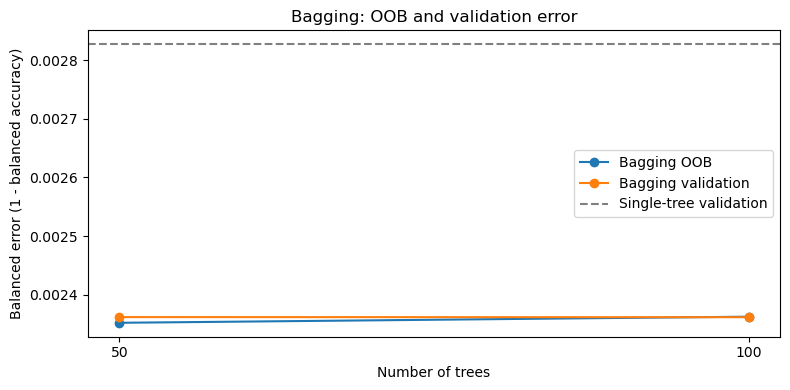

SINGLE TREE VERSUS SELECTED BAGGING - VALIDATION


,trees,balanced_accuracy,attack_precision,attack_recall,attack_f1,log_loss
Single tree,1,0.997173,0.994942,0.995374,0.995158,0.054473
Bagging,50,0.997638,0.995647,0.996161,0.995904,0.019956


In [11]:
# Purpose: Plot bagging OOB and validation balanced error against tree count.
# Explain: Compare with the single-tree reference; lower balanced error means better average class recall.

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(
    bagging_results.index, bagging_results["oob_balanced_error"],
    marker="o", label="Bagging OOB",
)
ax.plot(
    bagging_results.index, bagging_results["validation_balanced_error"],
    marker="o", label="Bagging validation",
)
ax.axhline(
    1 - baseline_validation_results.loc["Decision tree", "balanced_accuracy"],
    linestyle="--", color="gray", label="Single-tree validation",
)
ax.set(
    xlabel="Number of trees",
    ylabel="Balanced error (1 - balanced accuracy)",
    title="Bagging: OOB and validation error",
    xticks=TREE_COUNTS,
)
ax.legend()
fig.tight_layout()
plt.show()

metric_columns = list(baseline_validation_results.columns)
bagging_comparison = pd.DataFrame({
    "Single tree": baseline_validation_results.loc["Decision tree"],
    "Bagging": bagging_results.loc[selected_bagging_trees, metric_columns],
}).T
bagging_comparison.insert(0, "trees", [1, selected_bagging_trees])

print("SINGLE TREE VERSUS SELECTED BAGGING - VALIDATION")
display(bagging_comparison)


### Interpretation

Lower balanced error means better average recall across benign and attack flows. The horizontal line marks the single-tree reference. If the 50- and 100-tree results are close, that suggests limited additional benefit over this tested range; it does not establish a plateau beyond 100 trees. Agreement between OOB and validation error provides an internal consistency check, although the two estimates use different voting populations and may differ.

Use the comparison table to assess balanced accuracy, missed attacks through attack recall, false alarms through precision, and probability quality through log loss. Better log loss can be useful even when class predictions change little. These results compare aggregation with one tree; they do not yet establish that random feature selection helps. The next task will add the required random-forest grid and the final three-model comparison.


## Task 10 - Random-forest validation grid

**Objective.** Compare the eight required configurations: 100 or 300 trees, `mtry = sqrt(d)` or `d`, and minimum leaf size equal to the Lab 2 value (1) or 5. Here `d` is the number of encoded predictors in `X_train`. Retain the selected unlimited maximum depth and seed 42.

Use validation balanced accuracy for selection. Configurations within 0.0001 of the highest balanced accuracy are practically tied; prefer fewer trees, then fewer total fitted nodes. OOB balanced error provides an internal comparison.

For each feature/leaf setting, `warm_start=True` grows the 100-tree forest to 300 by adding 200 trees. The saved model preserves the 100-tree candidate for selection. This avoids refitting its first 100 trees. Progress is printed during each fit. These cells can be authored now and executed later on the chosen compute environment; no subsampling or feature changes are introduced.

The `mtry=d`, minimum-leaf-size-1, 100-tree configuration is identical to the 100-tree bagging configuration in this implementation. Its existing model and validation/OOB results are reused. Candidate models are stored on disk rather than kept as eight large in-memory copies.


In [12]:
# Purpose: Evaluate the fixed RF grid for feature candidates, minimum leaf size, and tree count.
# Explain: Select by validation BA; practical ties favor smaller models, not the best OOB result.

from sklearn.ensemble import RandomForestClassifier

RF_TREE_COUNTS = [100, 300]
# sqrt(d) restricts candidate predictors; 1.0 offers all predictors at each split.
RF_MAX_FEATURES = {"sqrt(d)": "sqrt", "d": 1.0}
# A minimum leaf size of 5 forbids splits creating a child with fewer than five samples.
RF_MIN_LEAF_SIZES = [single_tree_model.min_samples_leaf, 5]
RF_TIE_TOLERANCE = 0.0001

rf_model_files = {}
rf_rows = []
rf_validation_confusions = {}

for mtry_name, max_features in RF_MAX_FEATURES.items():
    for leaf_size in RF_MIN_LEAF_SIZES:
        forest = RandomForestClassifier(
            max_features=max_features,
            min_samples_leaf=leaf_size,
            max_depth=single_tree_model.max_depth,
            bootstrap=True, oob_score=True, warm_start=True,
            random_state=RANDOM_SEED, n_jobs=CPU_WORKERS, verbose=1,
        )
        for tree_count in RF_TREE_COUNTS:
            forest.set_params(n_estimators=tree_count)
            cache_path = model_cache_path(forest)
            if cache_path.exists():
                print(
                    f"Loading forest: mtry={mtry_name}, leaf={leaf_size}, "
                    f"trees={tree_count}", flush=True,
                )
                completed = joblib.load(cache_path)
                forest = completed["model"]
            else:
                print(
                    f"Growing forest: mtry={mtry_name}, leaf={leaf_size}, "
                    f"trees={tree_count}", flush=True,
                )
                forest.fit(X_train, y_train)
                metrics, confusion = ensemble_metrics(forest)
                completed = {"model": forest, "metrics": metrics, "confusion": confusion}
                save_fit(completed, cache_path)
            key = (mtry_name, leaf_size, tree_count)
            rf_model_files[key] = cache_path
            rf_validation_confusions[key] = completed["confusion"]
            rf_rows.append({
                "mtry": mtry_name,
                "min_samples_leaf": leaf_size,
                "trees": tree_count,
                **completed["metrics"],
                "total_nodes": sum(tree.tree_.node_count for tree in forest.estimators_),
            })
            pd.DataFrame(rf_rows).to_csv(
                RUN_DIRECTORY / "rf_validation_results.csv", index=False
            )
            print(
                f"Validation balanced accuracy: "
                f"{completed['metrics']['balanced_accuracy']:.6f}", flush=True,
            )

# Index results by candidate features per split, minimum leaf size, and tree count.
rf_results = pd.DataFrame(rf_rows).set_index(["mtry", "min_samples_leaf", "trees"])
# Higher validation balanced accuracy is better.
best_rf_score = rf_results["balanced_accuracy"].max()
# Keep scores within the declared tolerance of the best.
# Sort first by fewer trees, then fewer total nodes; other fields break ties.
rf_tied_candidates = rf_results.loc[
    rf_results["balanced_accuracy"] >= best_rf_score - RF_TIE_TOLERANCE
].reset_index().sort_values(["trees", "total_nodes", "mtry", "min_samples_leaf"])
# Take the preferred candidate and reconstruct its lookup key.
selected_rf_settings = rf_tied_candidates.iloc[0]
selected_rf_key = (
    selected_rf_settings["mtry"],
    int(selected_rf_settings["min_samples_leaf"]),
    int(selected_rf_settings["trees"]),
)
rf_model = joblib.load(rf_model_files[selected_rf_key])["model"]
print("RANDOM-FOREST VALIDATION GRID")
display(rf_results)
print("SELECTED RANDOM-FOREST CONFIGURATION")
display(selected_rf_settings.to_frame("value"))
print("SELECTED RANDOM-FOREST VALIDATION CONFUSION MATRIX")
display(pd.DataFrame(
    rf_validation_confusions[selected_rf_key],
    index=["actual BENIGN", "actual ATTACK"],
    columns=["predicted BENIGN", "predicted ATTACK"],
))
del completed, forest


Loading forest: mtry=sqrt(d), leaf=1, trees=100


Validation balanced accuracy: 0.997259
Loading forest: mtry=sqrt(d), leaf=1, trees=300
Validation balanced accuracy: 0.997280
Loading forest: mtry=sqrt(d), leaf=5, trees=100
Validation balanced accuracy: 0.942242
Loading forest: mtry=sqrt(d), leaf=5, trees=300
Validation balanced accuracy: 0.943878
Loading forest: mtry=d, leaf=1, trees=100
Validation balanced accuracy: 0.997638
Loading forest: mtry=d, leaf=1, trees=300
Validation balanced accuracy: 0.997689
Loading forest: mtry=d, leaf=5, trees=100
Validation balanced accuracy: 0.998815
Loading forest: mtry=d, leaf=5, trees=300
Validation balanced accuracy: 0.998802
RANDOM-FOREST VALIDATION GRID


balanced_accuracy  attack_precision  \
mtry    min_samples_leaf trees                                        
sqrt(d) 1                100             0.997259          0.996473   
                         300             0.997280          0.996509   
        5                100             0.942242          0.989605   
                         300             0.943878          0.989940   
d       1                100             0.997638          0.995763   
                         300             0.997689          0.995799   
        5                100             0.998815          0.996088   
                         300             0.998802          0.996134   

                                attack_recall  attack_f1  log_loss  \
mtry    min_samples_leaf trees                                       
sqrt(d) 1                100         0.995233   0.995853  0.008865   
                         300         0.995269   0.995888  0.006572   
        5                100         0.886375   0.935150  0.125262   
                         300         0.889592   0.937087  0.118445   
d       1                100         0.996137   0.995950  0.019544   
                         300         0.996231   0.996015  0.019273   
        5                100         0.998427   0.997256  0.004916   
                         300         0.998392   0.997262  0.004525   

                                oob_balanced_error  validation_balanced_error  \
mtry    min_samples_leaf trees                                                  
sqrt(d) 1                100              0.002752                   0.002741   
                         300              0.002717                   0.002720   
        5                100              0.064868                   0.057758   
                         300              0.060588                   0.056122   
d       1                100              0.002363                   0.002362   
                         300              0.002321                   0.002311   
        5                100              0.001307                   0.001185   
                         300              0.001281                   0.001198   

                                rows_without_oob_prediction  total_nodes  
mtry    min_samples_leaf trees                                            
sqrt(d) 1                100                              0      3229228  
                         300                              0      9700176  
        5                100                              0        84704  
                         300                              0       259822  
d       1                100                              0       326672  
                         300                              0       980388  
        5                100                              0       149864  
                         300                              0       449894

SELECTED RANDOM-FOREST CONFIGURATION


,value
mtry,d
min_samples_leaf,5
trees,100
balanced_accuracy,0.998815
attack_precision,0.996088
attack_recall,0.998427
attack_f1,0.997256
log_loss,0.004916
oob_balanced_error,0.001307
validation_balanced_error,0.001185


SELECTED RANDOM-FOREST VALIDATION CONFUSION MATRIX


,predicted BENIGN,predicted ATTACK
actual BENIGN,418963,334
actual ATTACK,134,85041


### Interpretation

The grid separates the effects of tree count, feature randomization, and minimum leaf size. Selection gives equal weight to benign and attack recall and favors a smaller model when scores are practically tied. The OOB coverage count reports any rows omitted from the OOB calculation.

The selected configuration and its confusion matrix will be available after execution. The test partition has not been used for these choices. A forest using `mtry=d` offers all predictors at each split; `sqrt(d)` adds feature randomization to bootstrap sampling.

## Task 11 - Complete the Part 2 comparison

**Objective.** Put bagging and the selected random-forest configuration on one OOB/validation error plot and compare the single tree, bagging, and random forest. Also compare `sqrt(d)` with `d` at identical leaf size and tree count, so the effect of feature randomization is assessed without changing those controls.

Run this cell after both the bagging and random-forest searches have completed in the execution environment.


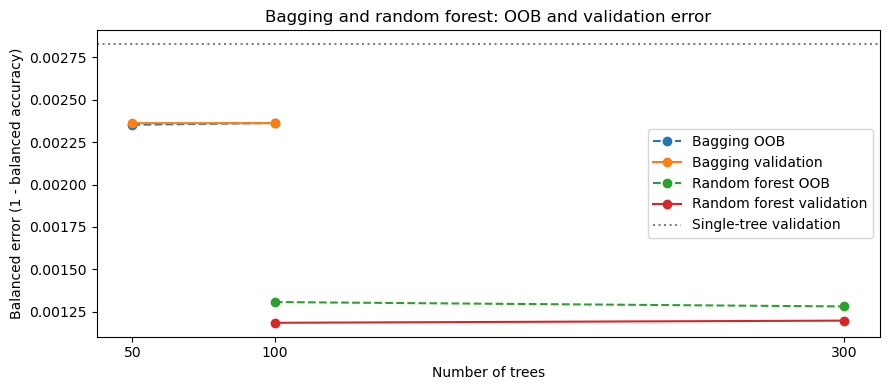

PART 2 - VALIDATION COMPARISON


,trees,balanced_accuracy,attack_precision,attack_recall,attack_f1,log_loss
Single tree,1,0.997173,0.994942,0.995374,0.995158,0.054473
Bagging,50,0.997638,0.995647,0.996161,0.995904,0.019956
Random forest,100,0.998815,0.996088,0.998427,0.997256,0.004916


FEATURE-RANDOMIZATION COMPARISON AT THE SAME LEAF SIZE AND TREE COUNT


,balanced_accuracy,attack_precision,attack_recall,attack_f1,log_loss
mtry,,,,,
sqrt(d),0.942242,0.989605,0.886375,0.935150,0.125262
d,0.998815,0.996088,0.998427,0.997256,0.004916


Balanced-accuracy change, sqrt(d) minus d: -0.056573


In [13]:
# Purpose: Compare the selected forest with bagging and the single tree.
# Explain: If selected mtry is all features, its gain cannot be credited to feature randomization.

selected_mtry, selected_leaf_size, selected_rf_trees = selected_rf_key
selected_rf_curve = rf_results.xs(
    (selected_mtry, selected_leaf_size),
    level=("mtry", "min_samples_leaf"),
).sort_index()

fig, ax = plt.subplots(figsize=(9, 4))
for label, results in [
    ("Bagging", bagging_results),
    ("Random forest", selected_rf_curve),
]:
    ax.plot(
        results.index, results["oob_balanced_error"],
        marker="o", linestyle="--", label=f"{label} OOB",
    )
    ax.plot(
        results.index, results["validation_balanced_error"],
        marker="o", label=f"{label} validation",
    )
ax.axhline(
    1 - baseline_validation_results.loc["Decision tree", "balanced_accuracy"],
    color="gray", linestyle=":", label="Single-tree validation",
)
ax.set(
    xlabel="Number of trees",
    ylabel="Balanced error (1 - balanced accuracy)",
    title="Bagging and random forest: OOB and validation error",
    xticks=sorted(set(TREE_COUNTS + RF_TREE_COUNTS)),
)
ax.legend()
fig.tight_layout()
plt.show()

metric_columns = list(baseline_validation_results.columns)
part2_validation_results = pd.DataFrame({
    "Single tree": baseline_validation_results.loc["Decision tree"],
    "Bagging": bagging_results.loc[selected_bagging_trees, metric_columns],
    "Random forest": rf_results.loc[selected_rf_key, metric_columns],
}).T
part2_validation_results.insert(
    0, "trees", [1, selected_bagging_trees, selected_rf_trees]
)

mtry_comparison = rf_results.xs(
    (selected_leaf_size, selected_rf_trees),
    level=("min_samples_leaf", "trees"),
)[metric_columns]
mtry_balanced_accuracy_change = (
    mtry_comparison.loc["sqrt(d)", "balanced_accuracy"]
    - mtry_comparison.loc["d", "balanced_accuracy"]
)

print("PART 2 - VALIDATION COMPARISON")
display(part2_validation_results)
print("FEATURE-RANDOMIZATION COMPARISON AT THE SAME LEAF SIZE AND TREE COUNT")
display(mtry_comparison)
print(
    "Balanced-accuracy change, sqrt(d) minus d: "
    f"{mtry_balanced_accuracy_change:+.6f}"
)


### Interpretation

The combined plot shows whether increasing tree count stabilizes OOB and validation error. The three-model table compares detection and probability quality on identical validation rows. Interpret any improvement alongside the single tree's already high balanced accuracy and the added computation.

The controlled feature comparison holds leaf size and tree count fixed. A positive `sqrt(d) minus d` difference means feature randomization improved validation balanced accuracy at those settings; a negative value means it reduced it. A difference within the declared practical-tie tolerance is weak evidence of a useful detection gain. Random feature selection can reduce shared errors, but can also weaken individual splits.

After execution, use the observed tables to state whether aggregation and feature randomization helped. Part 3 will compare gradient boosting and XGBoost using validation log loss and early stopping.


# Part 3 - Gradient boosting and XGBoost

## Task 12 - Declare the deadline experiment

**Objective.** Preserve all completed full-data baseline, bagging, random-forest and standard-gradient-boosting results. Run the remaining experiments under a declared, reduced computational budget.

**Amendment, 2026-10-29.** The full-data XGBoost fit was interrupted after 145 fully evaluated rounds and recovered separately. The original lab's 24-case XGBoost grid is not completed. The new search uses a fixed 50,000-row training sample and a 20,000-row stopping-validation sample from the original partitions. Sample proportionally by original attack category, reserving at least one row per category; save the selected row IDs and class counts. Preserve all 47,864 encoded predictors and the original training-fitted preprocessing. The final test partition is never sampled for scoring or used for tuning.

XGBoost now tests **learning rate 0.10, depth 3, lambda 0/1/10, gamma 0/0.1** (6 cases). Use histogram bin cap 32, at most 100 rounds, stopping patience 15 and a **10-minute soft budget per fit**, checked after each fully evaluated round. Checkpoint every round. These changes are computational compromises, not a claim that omitted settings are inferior. Stop reasons are reported; a time limit or round cap does not imply convergence.

After sample-validation selection, compare only that candidate and the recovered original model on the full original validation set. Freeze the lower-log-loss model before test evaluation. This is a declared two-candidate validation choice, not an exhaustive full-data search. Unequal training sizes limit causal algorithm comparisons.

The completed four standard-gradient-boosting cases remain unchanged. Later multiclass fits and fresh-fit cost proxies use their own fixed samples, documented below. These departures from the original requirements must be included in the report and, where necessary, approved by the instructor.


In [19]:
# Purpose: Declare full-data GB settings and the reduced deadline XGBoost protocol.
# Explain: The reduced XGBoost samples/grid are disclosed departures from the original full-data search.

from itertools import product
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import log_loss
from scipy.special import expit
from xgboost import XGBClassifier
from xgboost.callback import EarlyStopping
from deadline_helpers import proportional_sample, experiment_path, fit_xgb, atomic_joblib
import time

# Completed standard-gradient-boosting experiment: unchanged.
BOOST_LEARNING_RATES = [0.03, 0.10]
BOOST_DEPTHS = [1, 3]
BOOST_MAX_ROUNDS = 500
BOOST_PATIENCE = 20

# New deadline experiment: do not change after seeing its results.
DEADLINE_PROTOCOL = {
    "revision": "lab3_deadline_v1", "seed": RANDOM_SEED,
    "binary_training_rows": 50_000, "binary_stopping_rows": 20_000,
    "learning_rates": [0.10], "depths": [3],
    "l2_penalties": [0, 1, 10], "split_gains": [0, 0.1],
    "max_bin": 32, "maximum_rounds": 100, "patience": 15,
    "binary_seconds_per_fit": 600,
    "multiclass_training_rows": 20_000, "multiclass_stopping_rows": 10_000,
    "multiclass_seconds_per_fit": 900, "multiclass_round_cap": 100,
    "importance_rows": 5_000, "importance_repeats": 2,
    "cost_training_rows": 2_000, "cost_stopping_rows": 2_000, "cost_prediction_rows": 1_000,
    "cost_seconds_per_boosting_fit": 300,
}
display(pd.Series(DEADLINE_PROTOCOL, name="setting").to_frame())
print("Soft time limits are checked between rounds/stages, not hard process timeouts.")


,setting
revision,lab3_deadline_v1
seed,42
binary_training_rows,50000
binary_stopping_rows,20000
learning_rates,[0.1]
depths,[3]
l2_penalties,"[0, 1, 10]"
split_gains,"[0, 0.1]"
max_bin,32
maximum_rounds,100


Soft time limits are checked between rounds/stages, not hard process timeouts.


### Interpretation

This records a reduced, reproducible deadline protocol before the new fits. The original full-data observations and completed results remain available. Samples come only from their corresponding original training/validation partitions; the final test membership remains unchanged. Reserving rare categories slightly changes exact sample proportions, so the class-count audit must be retained.

## Task 13 - Completed standard gradient boosting

**Objective.** Reload the four saved full-data fits and their curves. The code below remains the original experiment and should load completed configurations rather than train them again. Its 500-round cap and patience 20 are not changed by the new XGBoost budget.


In [20]:
# Purpose: Fit standard gradient boosting and stop using external validation log loss.
# Explain: Retain the best stage after patience; the full loss history includes later discarded rounds.

def fit_gradient_boosting(
    model, train_features, train_labels, validation_features, validation_labels,
):
    # Initialize tracking state before training starts.
    history = []
    best_loss = np.inf
    best_round = 0
    validation_stages = None

    # The fitting loop calls this callback after each boosting stage.
    def monitor(iteration, model, fit_state):
        # Update state in the enclosing function so it persists between stages.
        nonlocal best_loss, best_round, validation_stages
        # Create an iterator for validation predictions through the growing stages.
        if iteration == 0:
            validation_stages = model.staged_predict_proba(validation_features)
        # Obtain this stage's validation probabilities and measure log loss.
        validation_probabilities = next(validation_stages)
        validation_loss = log_loss(
            validation_labels, validation_probabilities, labels=[0, 1]
        )
        # Convert training raw log-odds to probabilities for the learning curve.
        # Training loss is recorded, but it does not choose the stopping stage.
        training_probabilities = expit(fit_state["raw_predictions"].ravel())
        history.append({
            "round": iteration + 1,
            "training_log_loss": log_loss(
                train_labels, training_probabilities, labels=[0, 1]
            ),
            "validation_log_loss": validation_loss,
        })
        # Save the best validation loss and its one-based round number.
        if validation_loss < best_loss:
            best_loss = validation_loss
            best_round = iteration + 1
        # Print occasional progress; this does not affect model selection.
        if iteration == 0 or (iteration + 1) % 50 == 0:
            print(
                f"Round {iteration + 1}: validation log loss = {validation_loss:.6f}",
                flush=True,
            )
        # Returning True asks fitting to stop after patience rounds without a new best.
        return iteration + 1 - best_round >= BOOST_PATIENCE

    # Fit on training only; the monitor evaluates the separate validation set.
    model.fit(train_features, train_labels, monitor=monitor)

    # Retain only the fitted stages through the best validation round.
    # Discard later trees fitted while waiting for improvement.
    # For the selected run, 264 rounds were executed and 244 retained.
    model.estimators_ = model.estimators_[:best_round].copy()
    model.train_score_ = model.train_score_[:best_round].copy()
    # Keep the stored stage count and estimator parameter consistent with truncation.
    model.n_estimators_ = best_round
    model.set_params(n_estimators=best_round)
    # Return both the retained model and the full history, including discarded rounds.
    return model, pd.DataFrame(history)



gb_rows = []
gb_curves = {}
best_gb_loss = np.inf

for learning_rate, max_depth in product(BOOST_LEARNING_RATES, BOOST_DEPTHS):
    candidate = GradientBoostingClassifier(
        loss="log_loss", learning_rate=learning_rate, max_depth=max_depth,
        n_estimators=BOOST_MAX_ROUNDS, subsample=1.0, max_features=None,
        n_iter_no_change=None, random_state=RANDOM_SEED,
    )
    cache_path = model_cache_path(candidate, validation_patience=BOOST_PATIENCE)
    if cache_path.exists():
        print(f"Loading gradient boosting: eta={learning_rate}, depth={max_depth}", flush=True)
        completed = joblib.load(cache_path)
        candidate, curve = completed["model"], completed["curve"]
    else:
        print(f"Fitting gradient boosting: eta={learning_rate}, depth={max_depth}", flush=True)
        candidate, curve = fit_gradient_boosting(
            candidate, X_train, y_train, X_validation, y_validation,
        )
        save_fit({"model": candidate, "curve": curve}, cache_path)
    key = (learning_rate, max_depth)
    gb_curves[key] = curve
    selected_rounds = candidate.n_estimators_
    validation_loss = float(curve.loc[selected_rounds - 1, "validation_log_loss"])
    gb_rows.append({
        "learning_rate": learning_rate,
        "max_depth": max_depth,
        "rounds_run": len(curve),
        "selected_rounds": selected_rounds,
        "validation_log_loss": validation_loss,
    })
    pd.DataFrame(gb_rows).to_csv(RUN_DIRECTORY / "gb_validation_results.csv", index=False)
    curve.to_csv(RUN_DIRECTORY / f"gb_curve_{learning_rate}_{max_depth}.csv", index=False)
    if validation_loss < best_gb_loss:
        best_gb_loss = validation_loss
        gb_model = candidate
        selected_gb_key = key
    print(f"Best round: {selected_rounds}; validation log loss: {validation_loss:.6f}", flush=True)

gb_results = pd.DataFrame(gb_rows).set_index(["learning_rate", "max_depth"])
selected_gb_settings = gb_results.loc[selected_gb_key]
print("GRADIENT-BOOSTING VALIDATION GRID")
display(gb_results)
print("SELECTED GRADIENT-BOOSTING CONFIGURATION")
display(selected_gb_settings.to_frame("value"))
del candidate


Loading gradient boosting: eta=0.03, depth=1
Best round: 500; validation log loss: 0.087975
Loading gradient boosting: eta=0.03, depth=3
Best round: 500; validation log loss: 0.012342
Loading gradient boosting: eta=0.1, depth=1
Best round: 500; validation log loss: 0.034437
Loading gradient boosting: eta=0.1, depth=3
Best round: 244; validation log loss: 0.009014
GRADIENT-BOOSTING VALIDATION GRID


rounds_run  selected_rounds  validation_log_loss
learning_rate max_depth                                                  
0.03          1                 500              500             0.087975
              3                 500              500             0.012342
0.10          1                 500              500             0.034437
              3                 264              244             0.009014

SELECTED GRADIENT-BOOSTING CONFIGURATION


,value
rounds_run,264.000000
selected_rounds,244.000000
validation_log_loss,0.009014


### Interpretation

The standard-gradient-boosting search is complete. Three settings reached the 500-round cap; the learning-rate-0.10, depth-3 fit retained round 244 after validation stopping. A round cap alone is not evidence of stabilized validation loss.

## Task 14 - Budgeted XGBoost search and full-validation choice

**Objective.** Test six XGBoost configurations on fixed training/stopping samples. Save every completed evaluation round and distinguish early stopping, the round cap and the wall-time budget. Keep the recovered overnight model as a separate full-data candidate. Compare the sample-search winner with that recovered candidate on the full validation partition, then freeze the chosen model before examining test results.

This is not completion of the original 24-case grid. The helper uses all predictors and all rows **within each declared sample**, not all original training observations. Original training-only preprocessing is reused unchanged.


In [21]:
# Purpose: Run sampled XGBoost search and compare its winner with the recovered candidate on full validation.
# Explain: Freeze using validation only; unequal training resources prevent a pure algorithm ranking.

binary_train_positions = proportional_sample(
    multiclass_targets["train"], DEADLINE_PROTOCOL["binary_training_rows"], RANDOM_SEED,
)
binary_validation_positions = proportional_sample(
    multiclass_targets["validation"], DEADLINE_PROTOCOL["binary_stopping_rows"], RANDOM_SEED + 1,
)
DEADLINE_DIRECTORY = experiment_path(
    RUN_DIRECTORY, DEADLINE_PROTOCOL,
    partition_row_ids["train"][binary_train_positions],
    partition_row_ids["validation"][binary_validation_positions],
)
for partition, positions in [("train", binary_train_positions), ("validation", binary_validation_positions)]:
    pd.DataFrame({"row_id": partition_row_ids[partition][positions],
                  "original_class": multiclass_targets[partition][positions]}).to_csv(
        DEADLINE_DIRECTORY / f"binary_{partition}_sample.csv", index=False,
    )
    print(f"{partition}: {len(positions):,} sampled rows")
    display(pd.Series(multiclass_targets[partition][positions]).value_counts().sort_index().to_frame("sample_rows"))

sample_train_x = X_train[binary_train_positions]
sample_validation_x = X_validation[binary_validation_positions]
xgb_rows, xgb_curves, budget_xgb_files = [], {}, {}
for eta, depth, penalty, gain in product(
    DEADLINE_PROTOCOL["learning_rates"], DEADLINE_PROTOCOL["depths"],
    DEADLINE_PROTOCOL["l2_penalties"], DEADLINE_PROTOCOL["split_gains"],
):
    key = (eta, depth, penalty, gain)
    directory = DEADLINE_DIRECTORY / f"binary_xgb_{eta}_{depth}_{penalty}_{gain}"
    fitted = fit_xgb(
        {"learning_rate": eta, "max_depth": depth, "reg_lambda": penalty,
         "gamma": gain, "max_bin": DEADLINE_PROTOCOL["max_bin"]},
        sample_train_x, y_train[binary_train_positions],
        sample_validation_x, y_validation[binary_validation_positions], directory,
        max_rounds=DEADLINE_PROTOCOL["maximum_rounds"],
        seconds=DEADLINE_PROTOCOL["binary_seconds_per_fit"],
        patience=DEADLINE_PROTOCOL["patience"], workers=CPU_WORKERS,
    )
    xgb_curves[key] = fitted["curve"]
    budget_xgb_files[key] = directory / "fit.joblib"
    xgb_rows.append({"learning_rate": eta, "max_depth": depth, "reg_lambda": penalty, "gamma": gain,
                     **{k: fitted[k] for k in ["rounds_run", "selected_rounds", "fit_seconds", "termination_reason"]},
                     "validation_log_loss": float(fitted["curve"]["validation_log_loss"].min())})
    pd.DataFrame(xgb_rows).to_csv(DEADLINE_DIRECTORY / "xgb_sample_validation_grid.csv", index=False)

xgb_results = pd.DataFrame(xgb_rows).set_index(["learning_rate", "max_depth", "reg_lambda", "gamma"])
# Choose within the reduced search using the stopping-sample validation loss.
sample_winner = xgb_results.sort_values(["validation_log_loss", "selected_rounds"]).index[0]
budget_fit = joblib.load(budget_xgb_files[sample_winner])
# The recovery audit is explicit; no test results enter this choice.
choices = [{"source": "sample_search", "key": sample_winner, "model": budget_fit["model"],
            "curve": budget_fit["curve"], "training_rows": len(binary_train_positions),
            "stopping_rows": len(binary_validation_positions), "termination_reason": budget_fit["termination_reason"]}]
recovery_folders = sorted((RUN_DIRECTORY / "interrupted_xgboost").glob("*/recovery_metadata.json"))
if recovery_folders:
    recovered_folder = recovery_folders[-1].parent
    recovered_meta = json.loads(recovery_folders[-1].read_text())
    recovered_key = tuple(recovered_meta[k] for k in ["learning_rate", "max_depth", "reg_lambda", "gamma"])
    choices.append({"source": "recovered_full_training", "key": recovered_key,
                    "model": joblib.load(recovered_folder / "recovered_classifier.joblib"),
                    "curve": pd.read_csv(recovered_folder / "loss_curve.csv"),
                    "training_rows": len(y_train), "stopping_rows": len(y_validation),
                    "termination_reason": recovered_meta["termination_reason"]})
choice_rows = []
for choice in choices:
    probabilities = choice["model"].predict_proba(X_validation)
    choice["full_validation_log_loss"] = log_loss(y_validation, probabilities, labels=[0, 1])
    choice_rows.append({"source": choice["source"], "training_rows": choice["training_rows"],
                        "full_validation_log_loss": choice["full_validation_log_loss"],
                        "selected_rounds": choice["model"].get_booster().num_boosted_rounds()})
    del probabilities
# Compare only the declared candidates on FULL validation before any test evaluation.
selected_choice = min(choices, key=lambda choice: choice["full_validation_log_loss"])
xgb_model = selected_choice["model"]
selected_xgb_key = selected_choice["key"]
xgb_curves[selected_xgb_key] = selected_choice["curve"]
selected_xgb_settings = pd.Series({
    "selected_rounds": xgb_model.get_booster().num_boosted_rounds(),
    "validation_log_loss": float(selected_choice["curve"]["validation_log_loss"].min()),
    "full_validation_log_loss": selected_choice["full_validation_log_loss"],
})
selected_xgb_metadata = {k: selected_choice[k] for k in ["source", "training_rows", "stopping_rows", "termination_reason", "full_validation_log_loss"]}
xgb_search_complete = False  # Original full-data lab grid remains incomplete.
pd.DataFrame(choice_rows).to_csv(DEADLINE_DIRECTORY / "xgb_full_validation_choice.csv", index=False)
atomic_joblib({"model": xgb_model, "curve": selected_choice["curve"], "key": selected_xgb_key,
               "metadata": selected_xgb_metadata}, DEADLINE_DIRECTORY / "selected_xgb.joblib")
print("REDUCED SAMPLE-VALIDATION GRID")
display(xgb_results)
print("FULL-VALIDATION COMPARISON BEFORE TEST FREEZE")
display(pd.DataFrame(choice_rows).set_index("source"))
print("Chosen XGBoost source:", selected_xgb_metadata["source"])
del choices, budget_fit, fitted, sample_train_x, sample_validation_x


train: 50,000 sampled rows


,sample_rows
BENIGN,41546
Bot,40
DDoS,2538
DoS GoldenEye,205
DoS Hulk,3426
DoS Slowhttptest,105
DoS slowloris,108
FTP-Patator,118
Heartbleed,1
Infiltration,2


validation: 20,000 sampled rows


,sample_rows
BENIGN,16612
Bot,16
DDoS,1015
DoS GoldenEye,82
DoS Hulk,1371
DoS Slowhttptest,42
DoS slowloris,44
FTP-Patator,48
Heartbleed,1
Infiltration,1


Fitting binary_xgb_0.1_3_0_0: 50,000 train / 20,000 stopping rows
Round 1: validation loss=0.400340; elapsed=0.1 min
Round 10: validation loss=0.167227; elapsed=0.7 min
Round 20: validation loss=0.083517; elapsed=1.4 min
Round 30: validation loss=0.053303; elapsed=2.1 min
Round 40: validation loss=0.040185; elapsed=2.8 min
Round 50: validation loss=0.032486; elapsed=3.4 min
Round 60: validation loss=0.026847; elapsed=4.1 min
Round 70: validation loss=0.022020; elapsed=4.8 min
Round 80: validation loss=0.019556; elapsed=5.5 min
Round 90: validation loss=0.017037; elapsed=6.1 min
Round 100: validation loss=0.014957; elapsed=6.8 min
Fitting binary_xgb_0.1_3_0_0.1: 50,000 train / 20,000 stopping rows
Round 1: validation loss=0.400340; elapsed=0.1 min
Round 10: validation loss=0.167227; elapsed=0.7 min
Round 20: validation loss=0.083517; elapsed=1.4 min
Round 30: validation loss=0.053303; elapsed=2.1 min
Round 40: validation loss=0.040184; elapsed=2.7 min
Round 50: validation loss=0.032487;

rounds_run  selected_rounds  \
learning_rate max_depth reg_lambda gamma                                
0.1           3         0          0.0           100              100   
                                   0.1           100              100   
                        1          0.0           100              100   
                                   0.1           100              100   
                        10         0.0           100              100   
                                   0.1           100              100   

                                          fit_seconds termination_reason  \
learning_rate max_depth reg_lambda gamma                                   
0.1           3         0          0.0     409.295919          round_cap   
                                   0.1     409.789730          round_cap   
                        1          0.0     405.346512          round_cap   
                                   0.1     417.926194          round_cap   
                        10         0.0     406.393477          round_cap   
                                   0.1     407.385806          round_cap   

                                          validation_log_loss  
learning_rate max_depth reg_lambda gamma                       
0.1           3         0          0.0               0.014957  
                                   0.1               0.014854  
                        1          0.0               0.015250  
                                   0.1               0.015250  
                        10         0.0               0.017261  
                                   0.1               0.017261

FULL-VALIDATION COMPARISON BEFORE TEST FREEZE


,training_rows,full_validation_log_loss,selected_rounds
source,,,
sample_search,50000,0.015812,100
recovered_full_training,1513417,0.038785,145


Chosen XGBoost source: sample_search


### Interpretation

Use the reported stop reason, not just the tree count. `wall_budget` and `recovered_checkpoint` are partial fits; `round_cap` means the predeclared cap was reached; only `early_stopping` means the patience condition was met. Results from the smaller stopping sample are not directly comparable with full-validation losses until the explicit full-validation comparison.

The recovered full-data model and the sample-search winner have different fitting resources. Their final test comparison with other families is therefore a resource-constrained experiment, not a controlled estimate of algorithm superiority. None of these choices used test performance.

## Task 15 - Freeze the six selected binary models

**Objective.** Record each model's provenance, plot both selected boosting curves, and save the selected models before evaluating the common untouched test partition. Note that the XGBoost curve may use the stopping sample whereas the standard-gradient-boosting curve uses full validation.


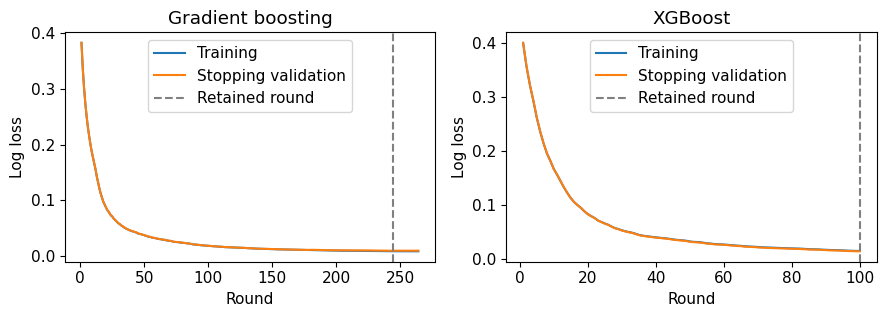

,learning_rate,max_depth,selected_rounds,reg_lambda,gamma,curve_validation_rows,training_rows,full_validation_log_loss,search_status
model,,,,,,,,,
Gradient boosting,0.1,3,244,NaN,NaN,504472,1513417,0.009014,original_4_cases_completed
XGBoost,0.1,3,100,0.0,0.1,20000,50000,0.015812,reduced_budget_experiment


Frozen model bundle: ./Lab3/artifacts/runs/dfd699ed631cec5e90e1deb652a1c3952c3f400a5263268db8eb5a9439c87319/deadline/f947ccc912146802fbae/selected_models.joblib


In [22]:
# Purpose: Freeze selected models and plot the selected boosting learning curves.
# Explain: GB and XGBoost curve populations differ; a round cap is not validation-patience stopping.

import matplotlib.pyplot as plt

selected_models = {
    "Logistic regression": logistic_model, "Decision tree": single_tree_model,
    "Bagging": bagging_model, "Random forest": rf_model,
    "Gradient boosting": gb_model, "XGBoost": xgb_model,
}
for model in selected_models.values():
    if isinstance(model, RandomForestClassifier):
        model.set_params(verbose=0)
part3_selected_settings = pd.DataFrame([
    {"model": "Gradient boosting", "learning_rate": selected_gb_key[0], "max_depth": selected_gb_key[1],
     "selected_rounds": gb_model.n_estimators_, "reg_lambda": np.nan, "gamma": np.nan,
     "curve_validation_rows": len(y_validation), "training_rows": len(y_train),
     "full_validation_log_loss": selected_gb_settings["validation_log_loss"], "search_status": "original_4_cases_completed"},
    {"model": "XGBoost", "learning_rate": selected_xgb_key[0], "max_depth": selected_xgb_key[1],
     "selected_rounds": xgb_model.get_booster().num_boosted_rounds(), "reg_lambda": selected_xgb_key[2], "gamma": selected_xgb_key[3],
     "curve_validation_rows": selected_xgb_metadata["stopping_rows"], "training_rows": selected_xgb_metadata["training_rows"],
     "full_validation_log_loss": selected_xgb_metadata["full_validation_log_loss"], "search_status": "reduced_budget_experiment"},
]).set_index("model")
plt.rcParams.update({"font.size": 11})
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
for ax, name, curve, rounds in [
    (axes[0], "Gradient boosting", gb_curves[selected_gb_key], gb_model.n_estimators_),
    (axes[1], "XGBoost", xgb_curves[selected_xgb_key], xgb_model.get_booster().num_boosted_rounds()),
]:
    ax.plot(curve["round"], curve["training_log_loss"], label="Training")
    ax.plot(curve["round"], curve["validation_log_loss"], label="Stopping validation")
    ax.axvline(rounds, color="gray", linestyle="--", label="Retained round")
    ax.set(title=name, xlabel="Round", ylabel="Log loss")
    ax.legend()
fig.tight_layout()
fig.savefig(DEADLINE_DIRECTORY / "boosting_curves.png", dpi=160)
plt.show()
part3_selected_settings.to_csv(DEADLINE_DIRECTORY / "selected_boosting_settings.csv")
display(part3_selected_settings)
# Refuse to silently replace a choice once its test bundle has been frozen.
freeze_configuration = {
    "models": {name: model.get_params(deep=False) for name, model in selected_models.items()},
    "xgb_provenance": selected_xgb_metadata,
}
freeze_text = json.dumps(freeze_configuration, sort_keys=True, default=str)
freeze_path = DEADLINE_DIRECTORY / "freeze_configuration.json"
if freeze_path.exists() and freeze_path.read_text() != freeze_text:
    raise RuntimeError("Model choice changed after freezing. Do not replace models using test results.")
if not freeze_path.exists():
    freeze_path.write_text(freeze_text)
# Write once: subsequent sections and reruns use this same frozen bundle.
if not (DEADLINE_DIRECTORY / "selected_models.joblib").exists():
    atomic_joblib(selected_models, DEADLINE_DIRECTORY / "selected_models.joblib")
selected_models = joblib.load(DEADLINE_DIRECTORY / "selected_models.joblib")
print("Frozen model bundle:", (DEADLINE_DIRECTORY / "selected_models.joblib").resolve())


### Interpretation

The configurations are now fixed without looking at test results. Standard gradient boosting follows the negative gradient and updates terminal leaf values; XGBoost uses gradients, Hessians, regularized split scores and regularized leaf outputs. Histogram split search, sampled training resources and the reduced grid are additional differences, so observed outcomes cannot be attributed to one mechanism alone.

Do not present the reduced XGBoost search as the original required grid. The provenance table and protocol record the limitations for the report.


# Part 4 - Final binary comparison and interpretation

## Task 16 - Evaluate the frozen models once on the common test rows

**Objective.** Evaluate all six frozen models on the same complete original test partition. Save metrics, predictions and confusion matrices so rerunning this cell reads the existing evaluation rather than repeatedly using the test set. Do not use these outputs to change a model.


Evaluating frozen model: Logistic regression
Evaluating frozen model: Decision tree
Evaluating frozen model: Bagging
Evaluating frozen model: Random forest
Evaluating frozen model: Gradient boosting
Evaluating frozen model: XGBoost


,balanced_accuracy,attack_precision,attack_recall,attack_f1,log_loss
model,,,,,
Logistic regression,0.955608,0.893575,0.933808,0.913248,0.068275
Decision tree,0.996963,0.995010,0.994940,0.994975,0.056055
Bagging,0.997520,0.995751,0.995903,0.995827,0.021205
Random forest,0.998793,0.996333,0.998333,0.997332,0.004587
Gradient boosting,0.996169,0.996313,0.993085,0.994696,0.008898
XGBoost,0.992247,0.996450,0.985207,0.990796,0.015730


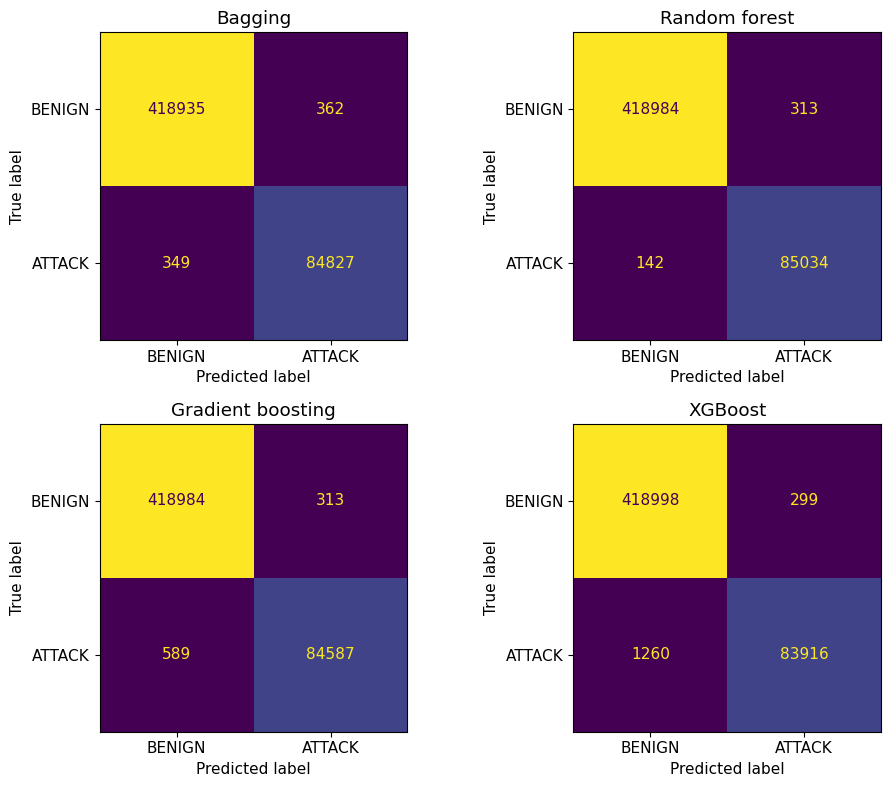

,row_id,original_class,actual,tree_prediction,rf_prediction,xgb_prediction,corrected_by_rf,corrected_by_xgb
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.c...,BENIGN,0,1,1,0,False,True
1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.c...,BENIGN,0,1,1,0,False,True
2,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.c...,BENIGN,0,1,0,0,True,True
3,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.c...,BENIGN,0,1,0,0,True,True
4,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.c...,BENIGN,0,1,0,0,True,True
5,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.c...,BENIGN,0,1,0,0,True,True
6,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.c...,BENIGN,0,1,0,0,True,True
7,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.c...,BENIGN,0,1,0,0,True,True
8,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.c...,DDoS,1,0,0,0,False,False
9,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.c...,DDoS,1,0,0,0,False,False


In [23]:
# Purpose: Evaluate all frozen binary models on the same untouched test rows.
# Explain: Compare decisions and probability loss; the ten inspected tree mistakes are illustrative, not representative.

from sklearn.metrics import ConfusionMatrixDisplay

test_file = DEADLINE_DIRECTORY / "binary_test_evaluation.joblib"
if test_file.exists():
    test_evaluation = joblib.load(test_file)
    if not np.array_equal(test_evaluation["row_ids"], partition_row_ids["test"]):
        raise ValueError("Saved test membership differs from this notebook.")
else:
    test_rows, test_predictions, test_confusions = [], {}, {}
    for name, model in selected_models.items():
        print("Evaluating frozen model:", name, flush=True)
        probabilities = model.predict_proba(X_test)
        predictions = model.classes_[np.argmax(probabilities, axis=1)]
        test_predictions[name] = predictions.astype(np.int8)
        test_confusions[name] = confusion_matrix(y_test, predictions, labels=[0, 1])
        test_rows.append({"model": name, "balanced_accuracy": balanced_accuracy_score(y_test, predictions),
                          "attack_precision": precision_score(y_test, predictions, zero_division=0),
                          "attack_recall": recall_score(y_test, predictions, zero_division=0),
                          "attack_f1": f1_score(y_test, predictions, zero_division=0),
                          "log_loss": log_loss(y_test, probabilities, labels=[0, 1])})
        del probabilities
    test_evaluation = {"metrics": pd.DataFrame(test_rows).set_index("model"),
                       "predictions": test_predictions, "confusions": test_confusions,
                       "row_ids": partition_row_ids["test"]}
    atomic_joblib(test_evaluation, test_file)
binary_test_results = test_evaluation["metrics"]
binary_test_results.to_csv(DEADLINE_DIRECTORY / "binary_test_results.csv")
display(binary_test_results)
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, name in zip(axes.flat, ["Bagging", "Random forest", "Gradient boosting", "XGBoost"]):
    matrix = test_evaluation["confusions"][name]
    pd.DataFrame(matrix, index=["BENIGN", "ATTACK"], columns=["BENIGN", "ATTACK"]).to_csv(
        DEADLINE_DIRECTORY / f"binary_confusion_{name.replace(' ', '_')}.csv")
    ConfusionMatrixDisplay(matrix, display_labels=["BENIGN", "ATTACK"]).plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(name)
fig.tight_layout()
fig.savefig(DEADLINE_DIRECTORY / "binary_confusions.png", dpi=160)
plt.show()

# Inspect the first ten tree errors, not ten cherry-picked corrections.
errors = np.flatnonzero(test_evaluation["predictions"]["Decision tree"] != y_test)[:10]
error_examples = pd.DataFrame({"row_id": partition_row_ids["test"][errors],
    "original_class": multiclass_targets["test"][errors], "actual": y_test[errors],
    "tree_prediction": test_evaluation["predictions"]["Decision tree"][errors],
    "rf_prediction": test_evaluation["predictions"]["Random forest"][errors],
    "xgb_prediction": test_evaluation["predictions"]["XGBoost"][errors]})
error_examples["corrected_by_rf"] = error_examples["rf_prediction"] == error_examples["actual"]
error_examples["corrected_by_xgb"] = error_examples["xgb_prediction"] == error_examples["actual"]
error_examples.to_csv(DEADLINE_DIRECTORY / "ten_tree_errors.csv", index=False)
display(error_examples)


### Interpretation

Read precision as the reliability of attack alarms and recall as the proportion of attacks detected. Balanced accuracy weights benign and attack recall equally; log loss measures probability quality. Use the confusion matrices to distinguish missed attacks from false alarms. The ten-flow inspection reports exactly which tree errors are corrected, rather than implying all are corrected.

All models share test rows, but the selected XGBoost model may have used fewer fitting rows. Report that resource difference alongside the comparison. No post-test tuning is permitted.

## Task 17 - Random-forest importance on validation only

**Objective.** Report the ten highest individual encoded-feature MDI importances. Also compare MDI and permutation importance at the level of all 69 original predictors: 68 numeric variables and one grouped Destination Port variable. Aggregate the port dummy MDI values and permute the whole port block together, preserving one-hot validity. Use a fixed 5,000-row original-class-proportional validation sample and two permutations per variable, scoring balanced accuracy.

Grouping the port levels is a documented interpretation choice, not 47,796 independent dummy permutations. The full grouped ranking and sample IDs are saved; permutation variability from two repeats is not a confidence interval.


Importance: 10/69 predictors
Importance: 20/69 predictors
Importance: 30/69 predictors
Importance: 40/69 predictors
Importance: 50/69 predictors
Importance: 60/69 predictors
TOP TEN ENCODED MDI FEATURES


,mdi
Bwd Packet Length Std,0.519393
Flow Bytes/s,0.114269
Average Packet Size,0.105287
Bwd Header Length,0.093112
Destination Port=80,0.022667
Idle Mean,0.019445
Max Packet Length,0.017095
Init_Win_bytes_forward,0.011539
Fwd Packet Length Std,0.011105
Destination Port=21,0.011092


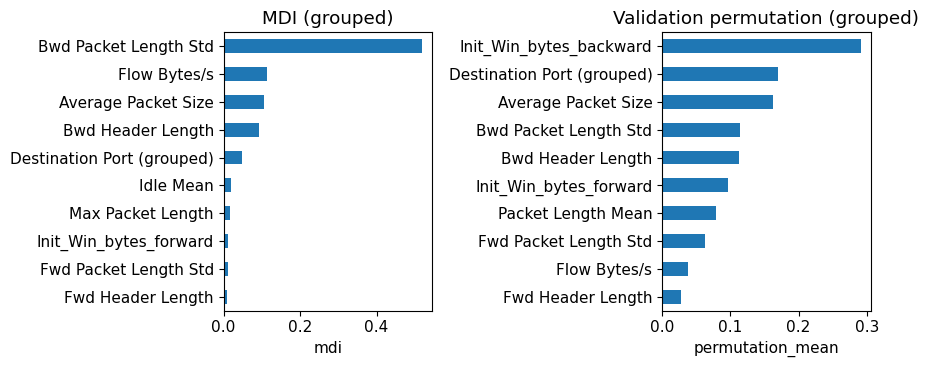

,permutation_mean,permutation_std,mdi
feature,,,
Init_Win_bytes_backward,0.291069,0.009285,0.007672
Destination Port (grouped),0.170283,0.001644,0.048503
Average Packet Size,0.162710,0.000403,0.105287
Bwd Packet Length Std,0.113578,0.000343,0.519393
Bwd Header Length,0.112369,0.002860,0.093112
Init_Win_bytes_forward,0.097002,0.002508,0.011539
Packet Length Mean,0.079178,0.000905,0.000380
Fwd Packet Length Std,0.063376,0.000292,0.011105
Flow Bytes/s,0.038491,0.001692,0.114269


Leading-feature correlated pair: ('Bwd Header Length', 'Fwd Header Length') correlation = 0.938226733434042
Largest observed rank difference: Flow IAT Max {'mdi': 29.0, 'permutation_mean': 69.0}


In [24]:
# Purpose: Compare training MDI split credit with validation permutation reliance.
# Explain: Shuffle the full one-hot port block together; correlation masks importance and neither measure is causal.

importance_file = DEADLINE_DIRECTORY / "importance_results.joblib"
if importance_file.exists():
    importance_results = joblib.load(importance_file)
else:
    importance_positions = proportional_sample(multiclass_targets["validation"], DEADLINE_PROTOCOL["importance_rows"], RANDOM_SEED + 2)
    numeric_sample = np.asarray(numeric_blocks["validation"][importance_positions], dtype=np.float32)
    port_sample = port_blocks["validation"][importance_positions].tocsr()
    importance_y = y_validation[importance_positions]
    rf_importance_model = selected_models["Random forest"]
    baseline_score = balanced_accuracy_score(importance_y, rf_importance_model.predict(
        hstack([csr_matrix(numeric_sample), port_sample], format="csr", dtype=np.float32)))
    rng = np.random.default_rng(RANDOM_SEED)
    importance_rows = []
    for column, feature in enumerate(numerical_features + ["Destination Port (grouped)"]):
        decreases = []
        for repeat in range(DEADLINE_PROTOCOL["importance_repeats"]):
            order = rng.permutation(len(importance_y))
            if column < len(numerical_features):
                changed_numeric = numeric_sample.copy()
                changed_numeric[:, column] = numeric_sample[order, column]
                changed = hstack([csr_matrix(changed_numeric), port_sample], format="csr", dtype=np.float32)
            # Shuffle the whole port block by row to preserve exactly one active port indicator.
            else:
                changed = hstack([csr_matrix(numeric_sample), port_sample[order]], format="csr", dtype=np.float32)
            score = balanced_accuracy_score(importance_y, rf_importance_model.predict(changed))
            decreases.append(baseline_score - score)
        importance_rows.append({"feature": feature, "permutation_mean": np.mean(decreases),
                                "permutation_std": np.std(decreases),
                                "mdi": (rf_importance_model.feature_importances_[column] if column < len(numerical_features)
                                        else rf_importance_model.feature_importances_[len(numerical_features):].sum())})
        if (column + 1) % 10 == 0:
            print(f"Importance: {column + 1}/69 predictors", flush=True)
    importance_results = {"grouped": pd.DataFrame(importance_rows).set_index("feature"),
                           "encoded": pd.Series(rf_importance_model.feature_importances_, index=complete_feature_names, name="mdi"),
                           "row_ids": partition_row_ids["validation"][importance_positions],
                           "correlation": pd.DataFrame(numeric_sample, columns=numerical_features).corr()}
    atomic_joblib(importance_results, importance_file)
importance_results["grouped"].to_csv(DEADLINE_DIRECTORY / "importance_all_original_predictors.csv")
importance_results["encoded"].sort_values(ascending=False).head(10).to_csv(DEADLINE_DIRECTORY / "mdi_encoded_top10.csv")
pd.Series(importance_results["row_ids"], name="row_id").to_csv(DEADLINE_DIRECTORY / "importance_validation_rows.csv", index=False)
print("TOP TEN ENCODED MDI FEATURES")
display(importance_results["encoded"].sort_values(ascending=False).head(10).to_frame())
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, metric, title in [(axes[0], "mdi", "MDI (grouped)"),
                           (axes[1], "permutation_mean", "Validation permutation (grouped)")]:
    top = importance_results["grouped"].nlargest(10, metric).sort_values(metric)
    top[metric].plot.barh(ax=ax)
    ax.set(title=title, xlabel=metric, ylabel="")
fig.tight_layout()
fig.savefig(DEADLINE_DIRECTORY / "importance_comparison.png", dpi=160)
plt.show()
display(importance_results["grouped"].nlargest(10, "permutation_mean"))
# Show the most correlated pair among the leading numerical importance variables.
leading = [f for f in importance_results["grouped"].nlargest(10, "mdi").index if f in numerical_features]
correlations = importance_results["correlation"].loc[leading, leading]
upper = correlations.where(np.triu(np.ones(correlations.shape, dtype=bool), k=1)).stack()
if len(upper):
    pair = upper.abs().idxmax()
    print("Leading-feature correlated pair:", pair, "correlation =", float(upper.loc[pair]))
importance_results["correlation"].to_csv(DEADLINE_DIRECTORY / "numerical_validation_correlations.csv")

importance_ranks = importance_results["grouped"][["mdi", "permutation_mean"]].rank(ascending=False, method="min")
rank_gap = (importance_ranks["mdi"] - importance_ranks["permutation_mean"]).abs()
rank_feature = rank_gap.idxmax()
print("Largest observed rank difference:", rank_feature, importance_ranks.loc[rank_feature].to_dict())


### Interpretation

MDI allocates training impurity reductions to chosen splits; permutation measures the loss in validation balanced accuracy when a predictor's information is disrupted. MDI can favor variables with many split opportunities. Correlated alternatives can share MDI or substitute for a permuted variable, masking its importance. A negative permutation estimate means the score improved under that perturbation; do not truncate it to zero.

Use the observed top-ten lists to describe an actual ranking difference. These are predictive associations, not evidence of causation. Destination-port importance may reflect scenario-specific service patterns.

# Part 5 - Multiclass and destination-port extension

## Task 18 - Matched sample experiments with and without port

**Objective.** Apply Lab 2 eligibility: at least 100 original training, 20 validation and 20 test observations per retained category. Save excluded counts. Use one fixed proportional 20,000-row eligible training sample and one 10,000-row eligible validation sample for both models and both representations. Keep all eligible test rows unchanged.

Use the selected binary RF/XGBoost settings, removing only Destination Port for the without-port representation. For XGBoost, use multiclass log loss and at most 100 rounds with validation stopping and a 15-minute soft budget. RF grows toward its selected tree count in 10-tree stages, checkpointing each stage; if its 15-minute soft budget is reached, report the actual count and the deviation. Sampling, reduced boosting cap and any stopped RF count depart from the original full-data experiment. Do not select hyperparameters using multiclass test results.


partition,train,validation,test,eligible
Label,,,,
BENIGN,1257890,419297,419297,True
Bot,1172,391,390,True
DDoS,76809,25603,25604,True
DoS GoldenEye,6172,2057,2057,True
DoS Hulk,103709,34570,34570,True
DoS Slowhttptest,3137,1045,1046,True
DoS slowloris,3231,1077,1077,True
FTP-Patator,3560,1186,1187,True
Heartbleed,7,2,2,False


,train,validation,test
BENIGN,16615,8303,419297
DoS Hulk,1371,685,34570
DDoS,1015,508,25604
PortScan,721,361,18164
DoS GoldenEye,83,42,2057
FTP-Patator,48,24,1187
DoS slowloris,44,22,1077
DoS Slowhttptest,42,22,1046
SSH-Patator,26,14,644
Bot,16,9,390


Multiclass RF without_port: growing to 10/100
Multiclass RF without_port: growing to 20/100
Multiclass RF without_port: growing to 30/100
Multiclass RF without_port: growing to 40/100
Multiclass RF without_port: growing to 50/100
Multiclass RF without_port: growing to 60/100
Multiclass RF without_port: growing to 70/100
Multiclass RF without_port: growing to 80/100
Multiclass RF without_port: growing to 90/100
Multiclass RF without_port: growing to 100/100
Fitting multiclass_XGBoost_without_port: 20,000 train / 10,000 stopping rows
Round 1: validation loss=1.945811; elapsed=0.0 min
Round 10: validation loss=0.647734; elapsed=0.0 min
Round 20: validation loss=0.267448; elapsed=0.0 min
Round 30: validation loss=0.124065; elapsed=0.0 min
Round 40: validation loss=0.068067; elapsed=0.0 min
Round 50: validation loss=0.044286; elapsed=0.0 min
Round 60: validation loss=0.032536; elapsed=0.0 min
Round 70: validation loss=0.026718; elapsed=0.0 min
Round 80: validation loss=0.023007; elapsed=0.0

,,macro_f1,training_rows,validation_rows,fit_seconds,termination_reason,boosting_rounds,fitted_trees
model,representation,,,,,,,
Random forest,without_port,0.808517,20000,10000,45.786551,requested_tree_count,NaN,100
XGBoost,without_port,0.813409,20000,10000,3.838329,round_cap,100.0,1200
Random forest,with_port,0.811813,20000,10000,54.965198,requested_tree_count,NaN,100
XGBoost,with_port,0.832962,20000,10000,197.581195,round_cap,100.0,1200


,Random forest / without_port,XGBoost / without_port,Random forest / with_port,XGBoost / with_port
BENIGN,0.997875,0.998896,0.998116,0.999237
Bot,0.323077,0.256410,0.248718,0.376923
DDoS,0.996133,0.998086,0.996329,0.998125
DoS GoldenEye,0.917355,0.938260,0.917842,0.950899
DoS Hulk,0.982557,0.988371,0.987966,0.994128
DoS Slowhttptest,0.717017,0.850860,0.717017,0.865201
DoS slowloris,0.839369,0.855153,0.839369,0.857010
FTP-Patator,0.979781,0.992418,0.991575,0.997473
PortScan,0.985246,0.990200,0.984695,0.986787
SSH-Patator,0.790373,0.909938,0.928571,0.973602


,Random forest,XGBoost
BENIGN,0.000241,0.000341
Bot,-0.074359,0.120513
DDoS,0.000195,0.000039
DoS GoldenEye,0.000486,0.012640
DoS Hulk,0.005409,0.005756
DoS Slowhttptest,0.000000,0.014340
DoS slowloris,0.000000,0.001857
FTP-Patator,0.011794,0.005055
PortScan,-0.000551,-0.003413
SSH-Patator,0.138199,0.063665


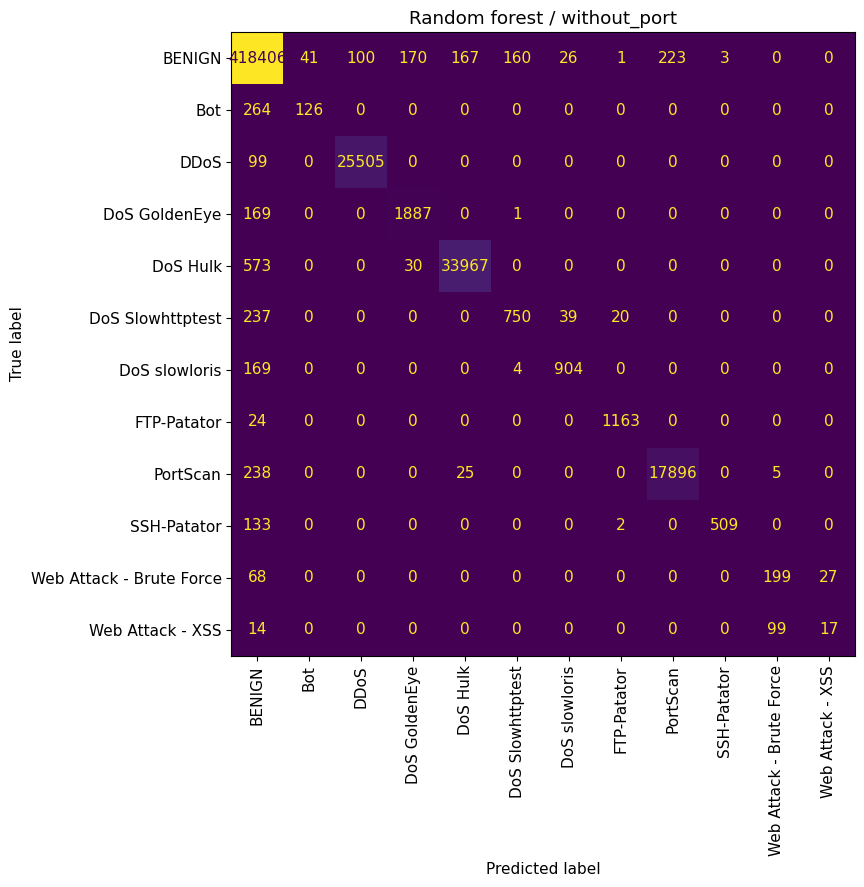

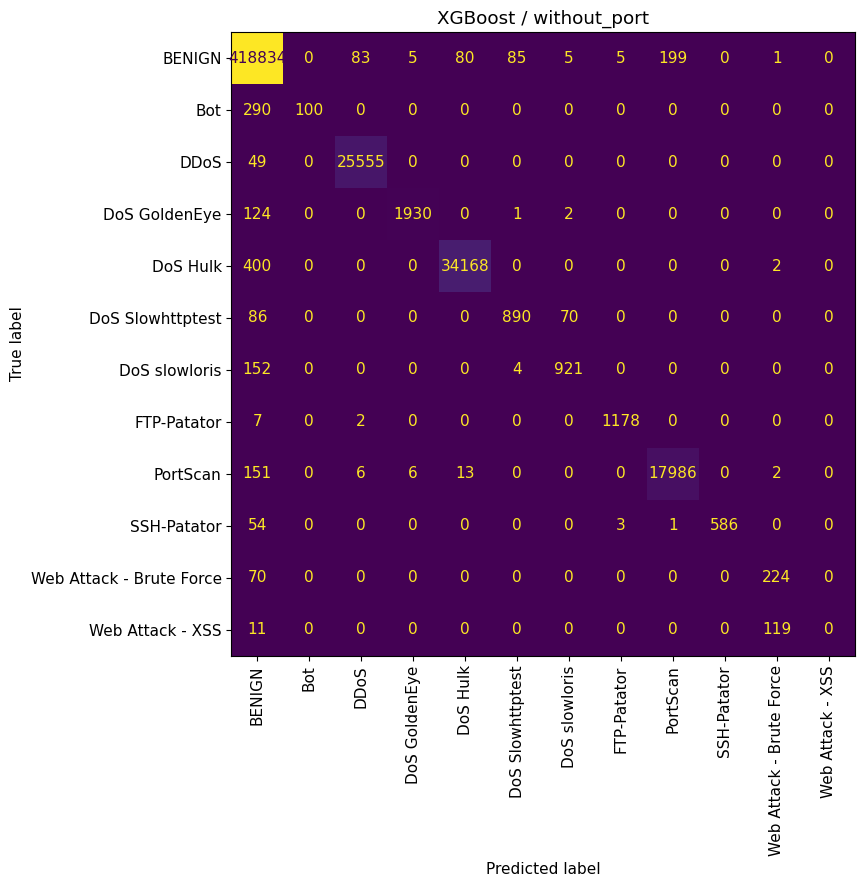

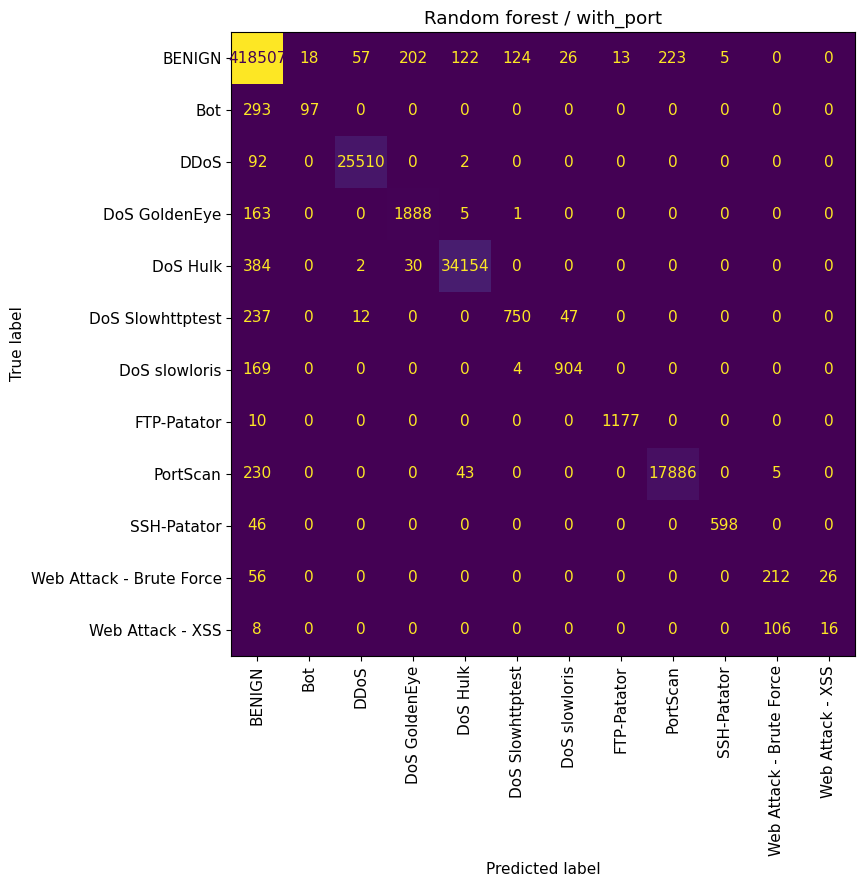

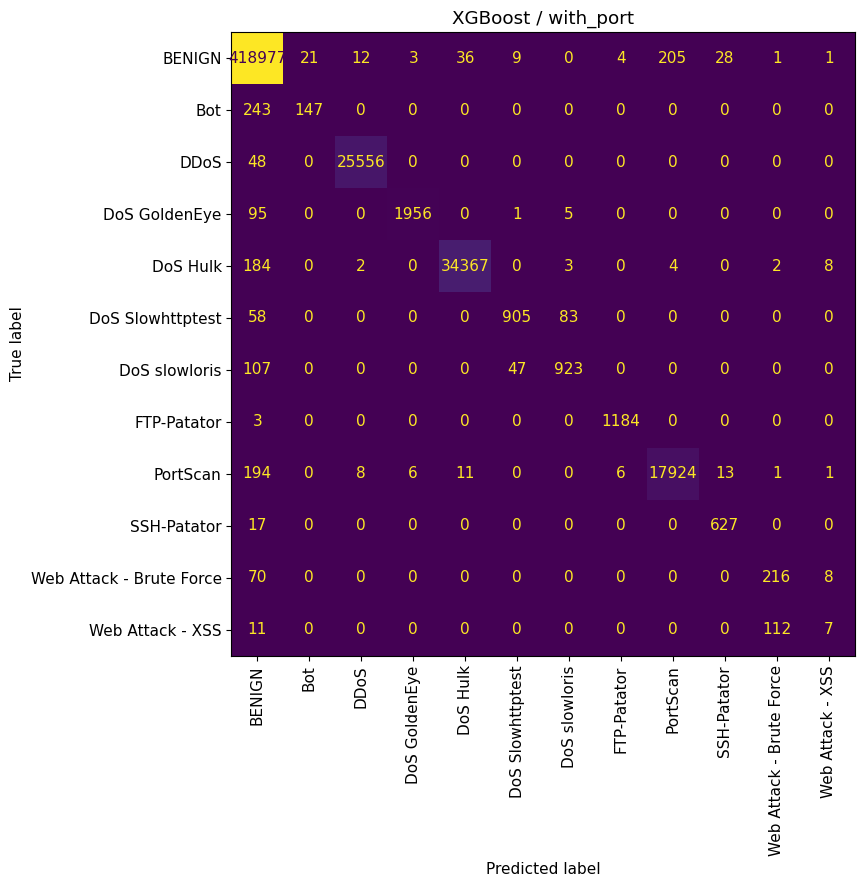

In [25]:
# Purpose: Compare paired multiclass RF/XGBoost fits with and without categorical port.
# Explain: Use fixed training/validation samples and all eligible test rows; rare sampled classes limit conclusions.

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import recall_score
from sklearn.base import clone

eligible_classes = multiclass_counts.index[(multiclass_counts["train"] >= 100) &
    (multiclass_counts["validation"] >= 20) & (multiclass_counts["test"] >= 20)].tolist()
multiclass_counts.assign(eligible=multiclass_counts.index.isin(eligible_classes)).to_csv(
    DEADLINE_DIRECTORY / "multiclass_eligibility.csv")
display(multiclass_counts.assign(eligible=multiclass_counts.index.isin(eligible_classes)))
label_encoder = LabelEncoder().fit(eligible_classes)
mc_positions = {}
for partition, size in [("train", DEADLINE_PROTOCOL["multiclass_training_rows"]),
                         ("validation", DEADLINE_PROTOCOL["multiclass_stopping_rows"]), ("test", None)]:
    allowed = np.flatnonzero(np.isin(multiclass_targets[partition], eligible_classes))
    positions = (allowed if size is None else allowed[proportional_sample(multiclass_targets[partition][allowed], size, RANDOM_SEED + (partition == "validation"))])
    mc_positions[partition] = positions
    pd.DataFrame({"row_id": partition_row_ids[partition][positions],
                  "original_class": multiclass_targets[partition][positions]}).to_csv(
        DEADLINE_DIRECTORY / f"multiclass_{partition}_rows.csv", index=False)
mc_targets = {partition: label_encoder.transform(multiclass_targets[partition][positions])
              for partition, positions in mc_positions.items()}
mc_count_table = pd.DataFrame({partition: pd.Series(multiclass_targets[partition][positions]).value_counts()
                               for partition, positions in mc_positions.items()}).fillna(0).astype(int)
mc_count_table.to_csv(DEADLINE_DIRECTORY / "multiclass_experiment_counts.csv")
display(mc_count_table)
mc_rows, mc_recalls, mc_confusions = [], {}, {}
for representation in ["without_port", "with_port"]:
    blocks = {partition: (csr_matrix(numeric_blocks[partition][positions], dtype=np.float32)
                          if representation == "without_port" else complete_blocks[partition][positions])
              for partition, positions in mc_positions.items()}
    for family in ["Random forest", "XGBoost"]:
        directory = DEADLINE_DIRECTORY / f"multiclass_{family.replace(' ', '_')}_{representation}"
        directory.mkdir(exist_ok=True)
        if family == "Random forest":
            path = directory / "fit.joblib"
            target_trees = selected_models["Random forest"].n_estimators
            params = selected_models["Random forest"].get_params(deep=False).copy()
            params.update(n_estimators=min(10, target_trees), warm_start=True, oob_score=False, verbose=0)
            if path.exists():
                fitted_mc = joblib.load(path)
                model = fitted_mc["model"]
            else:
                model = RandomForestClassifier(**params)
                start = time.perf_counter()
                completed_seconds = 0.0
                stage_path = directory / "stage.joblib"
                if stage_path.exists():
                    stage = joblib.load(stage_path)
                    model, completed_seconds = stage["model"], stage["fit_seconds"]
                while True:
                    if hasattr(model, "estimators_") and len(model.estimators_) >= target_trees:
                        break
                    next_count = min(target_trees, (len(model.estimators_) if hasattr(model, "estimators_") else 0) + 10)
                    model.set_params(n_estimators=next_count)
                    print(f"Multiclass RF {representation}: growing to {next_count}/{target_trees}", flush=True)
                    model.fit(blocks["train"], mc_targets["train"])
                    elapsed = completed_seconds + time.perf_counter() - start
                    atomic_joblib({"model": model, "fit_seconds": elapsed}, stage_path)
                    if elapsed >= DEADLINE_PROTOCOL["multiclass_seconds_per_fit"]:
                        break
                fitted_mc = {"model": model, "fit_seconds": completed_seconds + time.perf_counter() - start,
                             "termination_reason": "requested_tree_count" if len(model.estimators_) == target_trees else "wall_budget"}
                atomic_joblib(fitted_mc, path)
        else:
            params = selected_models["XGBoost"].get_params(deep=False)
            fitted_mc = fit_xgb(
                {k: (params[k] if params.get(k) is not None else 256) for k in ["learning_rate", "max_depth", "reg_lambda", "gamma", "max_bin"]},
                blocks["train"], mc_targets["train"], blocks["validation"], mc_targets["validation"], directory,
                max_rounds=DEADLINE_PROTOCOL["multiclass_round_cap"],
                seconds=DEADLINE_PROTOCOL["multiclass_seconds_per_fit"],
                patience=DEADLINE_PROTOCOL["patience"], workers=CPU_WORKERS)
            model = fitted_mc["model"]
        # Parameters and rounds are now fixed. Cache this representation's test evaluation.
        evaluation_path = directory / "test_evaluation.joblib"
        if evaluation_path.exists():
            evaluation = joblib.load(evaluation_path)
        else:
            predictions = model.predict(blocks["test"])
            evaluation = {"macro_f1": f1_score(mc_targets["test"], predictions, labels=np.arange(len(eligible_classes)), average="macro", zero_division=0),
                          "recall": recall_score(mc_targets["test"], predictions, labels=np.arange(len(eligible_classes)), average=None, zero_division=0),
                          "confusion": confusion_matrix(mc_targets["test"], predictions, labels=np.arange(len(eligible_classes)))}
            atomic_joblib(evaluation, evaluation_path)
        key = f"{family} / {representation}"
        mc_rows.append({"model": family, "representation": representation, "macro_f1": evaluation["macro_f1"],
                        "training_rows": len(mc_targets["train"]), "validation_rows": len(mc_targets["validation"]),
                        "fit_seconds": fitted_mc["fit_seconds"], "termination_reason": fitted_mc["termination_reason"],
                        "boosting_rounds": np.nan if family == "Random forest" else model.get_booster().num_boosted_rounds(),
                        "fitted_trees": len(model.estimators_) if family == "Random forest" else len(model.get_booster().get_dump())})
        mc_recalls[key] = evaluation["recall"]
        mc_confusions[key] = evaluation["confusion"]
        pd.DataFrame(mc_rows).to_csv(DEADLINE_DIRECTORY / "multiclass_results.csv", index=False)
    del blocks
multiclass_results = pd.DataFrame(mc_rows).set_index(["model", "representation"])
multiclass_recalls = pd.DataFrame(mc_recalls, index=label_encoder.classes_)
multiclass_recalls.to_csv(DEADLINE_DIRECTORY / "multiclass_class_recall.csv")
display(multiclass_results)
display(multiclass_recalls)
port_recall_gains = pd.DataFrame({family: multiclass_recalls[f"{family} / with_port"] - multiclass_recalls[f"{family} / without_port"]
                                 for family in ["Random forest", "XGBoost"]})
port_recall_gains.to_csv(DEADLINE_DIRECTORY / "destination_port_recall_change.csv")
display(port_recall_gains)
for name, matrix in mc_confusions.items():
    pd.DataFrame(matrix, index=label_encoder.classes_, columns=label_encoder.classes_).to_csv(
        DEADLINE_DIRECTORY / f"multiclass_confusion_{name.replace(' / ', '_').replace(' ', '_')}.csv")
    fig, ax = plt.subplots(figsize=(10, 9))
    ConfusionMatrixDisplay(matrix, display_labels=label_encoder.classes_).plot(ax=ax, colorbar=False, values_format="d", xticks_rotation=90)
    ax.set_title(name)
    fig.tight_layout()
    fig.savefig(DEADLINE_DIRECTORY / f"multiclass_confusion_{name.replace(' / ', '_').replace(' ', '_')}.png", dpi=160)
    plt.show()


### Interpretation

Macro-F1 gives each retained traffic category equal weight, exposing weak minority-class detection hidden by overall accuracy. State which classes have zero recall rather than suppressing them. The same sampled rows are used with and without port, making the representation comparison paired within this reduced experiment.

Describe the largest observed positive and negative port-related recall changes separately for RF and XGBoost. Service identity can help distinguish the recorded scenarios without proving generalization to other networks. If a time budget produces different fitted counts, the port ablation is not solely an encoding effect; explicitly acknowledge that confounder.

# Part 6 - Computational cost and recommendation

## Task 19 - Measure selected model inference/size and a fresh-fit cost proxy

**Objective.** Measure the frozen selected models' prediction time on the same fixed 1,000 test flows (timing only; never tuning), serialized size and actual tree count. Warm up once and report median of three prediction calls.

Full-data fresh fitting would repeat the multi-day run and was not measured consistently. Instead, clone the selected procedures and fit all four on the **same fixed 2,000 original training rows**, with the same two-worker environment. These fit times are explicitly **small-sample proxies, not full-data training times**; they do not satisfy a strict full-data timing comparison. XGBoost's cost proxy has a five-minute soft cap, whose stop reason and actual fitted count must be reported. This proxy never replaces a selected model or feeds test scoring.


In [26]:
# Purpose: Measure prediction/model costs and fresh-fit proxies under declared conditions.
# Explain: Fitting uses a 2,000-row proxy, not full-data timing; checkpoint overhead limits speed rankings.

import platform
import io

cost_file = DEADLINE_DIRECTORY / "computational_cost.csv"
if cost_file.exists() and len(pd.read_csv(cost_file)) == 4:
    computational_cost = pd.read_csv(cost_file).set_index("model")
else:
    cost_train_positions = proportional_sample(multiclass_targets["train"], DEADLINE_PROTOCOL["cost_training_rows"], RANDOM_SEED + 3)
    cost_validation_positions = proportional_sample(multiclass_targets["validation"], DEADLINE_PROTOCOL["cost_stopping_rows"], RANDOM_SEED + 4)
    cost_test_positions = np.arange(min(DEADLINE_PROTOCOL["cost_prediction_rows"], len(y_test)))
    cost_train_x = X_train[cost_train_positions]
    cost_predict_x = X_test[cost_test_positions]
    cost_rows = []
    for name in ["Decision tree", "Random forest", "Gradient boosting", "XGBoost"]:
        selected = selected_models[name]
        directory = DEADLINE_DIRECTORY / f"cost_{name.replace(' ', '_')}"
        directory.mkdir(exist_ok=True)
        if name == "XGBoost":
            params = selected.get_params(deep=False)
            fitted_cost = fit_xgb(
                {k: (params[k] if params.get(k) is not None else 256) for k in ["learning_rate", "max_depth", "reg_lambda", "gamma", "max_bin"]},
                cost_train_x, y_train[cost_train_positions], X_validation[cost_validation_positions], y_validation[cost_validation_positions],
                directory, max_rounds=selected.get_booster().num_boosted_rounds(),
                seconds=DEADLINE_PROTOCOL["cost_seconds_per_boosting_fit"], patience=10**9, workers=CPU_WORKERS)
            fresh = fitted_cost["model"]
            fit_seconds = fitted_cost["fit_seconds"]
            termination = fitted_cost["termination_reason"]
        else:
            path = directory / "fresh_fit.joblib"
            if path.exists():
                fitted_cost = joblib.load(path)
                fresh, fit_seconds = fitted_cost["model"], fitted_cost["fit_seconds"]
            else:
                fresh = clone(selected)
                if name == "Random forest":
                    fresh.set_params(verbose=0)
                print("Fresh small-sample timing:", name, flush=True)
                start = time.perf_counter()
                fresh.fit(cost_train_x, y_train[cost_train_positions])
                fit_seconds = time.perf_counter() - start
                atomic_joblib({"model": fresh, "fit_seconds": fit_seconds}, path)
            termination = "selected_settings_completed"
        selected.predict(cost_predict_x[:min(50, cost_predict_x.shape[0])])
        timings = []
        for repeat in range(3):
            start = time.perf_counter()
            selected.predict(cost_predict_x)
            timings.append(time.perf_counter() - start)
        model_path = directory / "selected_model.joblib"
        joblib.dump(selected, model_path, compress=3)
        count = (lambda model: model.get_booster().num_boosted_rounds() if name == "XGBoost" else
                 (int(np.asarray(model.estimators_, dtype=object).size) if hasattr(model, "estimators_") else 1))
        cost_rows.append({"model": name, "fresh_fit_proxy_seconds": fit_seconds,
                          "proxy_training_rows": len(cost_train_positions), "proxy_stop_reason": termination,
                          "proxy_fitted_trees": count(fresh), "selected_fitted_trees": count(selected),
                          "prediction_rows": len(cost_test_positions), "prediction_median_seconds": np.median(timings),
                          "selected_serialized_bytes_compress3": model_path.stat().st_size,
                          "full_training_fit_seconds": np.nan})
        pd.DataFrame(cost_rows).to_csv(cost_file, index=False)
    computational_cost = pd.DataFrame(cost_rows).set_index("model")
    pd.DataFrame({"row_id": partition_row_ids["train"][cost_train_positions]}).to_csv(DEADLINE_DIRECTORY / "cost_training_rows.csv", index=False)
    pd.DataFrame({"row_id": partition_row_ids["validation"][cost_validation_positions]}).to_csv(DEADLINE_DIRECTORY / "cost_validation_rows.csv", index=False)
    pd.DataFrame({"row_id": partition_row_ids["test"][cost_test_positions]}).to_csv(DEADLINE_DIRECTORY / "cost_prediction_rows.csv", index=False)
    (DEADLINE_DIRECTORY / "cost_environment.json").write_text(json.dumps({
        "platform": platform.platform(), "machine": platform.machine(), "workers": CPU_WORKERS,
        "software_versions": software_versions.to_dict(), "fit_measurement": "small-sample proxy, not full-data fit",
        "xgboost_proxy_includes_validation_evaluation": True,
        "comparison_caveat": "XGBoost records loss/checkpoints; sklearn proxies do not. Timings include these procedure-specific overheads."}, indent=2))
display(computational_cost)


Fresh small-sample timing: Decision tree
Fresh small-sample timing: Random forest
Fresh small-sample timing: Gradient boosting
Fitting cost_XGBoost: 2,000 train / 2,000 stopping rows
Round 1: validation loss=0.409121; elapsed=0.0 min
Round 10: validation loss=0.174505; elapsed=0.1 min
Round 20: validation loss=0.096901; elapsed=0.1 min
Round 30: validation loss=0.067745; elapsed=0.2 min
Round 40: validation loss=0.055602; elapsed=0.2 min
Round 50: validation loss=0.045719; elapsed=0.3 min
Round 60: validation loss=0.040963; elapsed=0.4 min
Round 70: validation loss=0.036781; elapsed=0.4 min
Round 80: validation loss=0.033636; elapsed=0.5 min
Round 90: validation loss=0.030891; elapsed=0.5 min
Round 100: validation loss=0.028717; elapsed=0.6 min


,fresh_fit_proxy_seconds,proxy_training_rows,proxy_stop_reason,proxy_fitted_trees,selected_fitted_trees,prediction_rows,prediction_median_seconds,selected_serialized_bytes_compress3,full_training_fit_seconds
model,,,,,,,,,
Decision tree,0.104165,2000,selected_settings_completed,1,1,1000,0.000632,76397,NaN
Random forest,2.859422,2000,selected_settings_completed,100,100,1000,0.034733,4346469,NaN
Gradient boosting,8.318934,2000,selected_settings_completed,244,244,1000,0.007050,144903,NaN
XGBoost,35.570242,2000,round_cap,100,100,1000,0.004451,23335,NaN


### Interpretation

Do not equate loading a cached model with fitting it. Full-data fit times are left missing rather than invented. The fresh-fit proxy uses common rows/hardware but much smaller data; model complexity and runtime need not scale linearly. XGBoost's proxy includes validation/checkpoint overhead; note this procedural difference. The serialized sizes use the same joblib compression, and prediction times refer to the same flow count.

Recommend a model for a stated scenario using detection errors, probability quality, inference cost and interpretability together. A lightweight deployment can reasonably prioritize the single tree or compact forest; a different setting may prioritize probabilistic quality. Do not choose new hyperparameters after seeing test results.

## Task 20 - Export submission evidence and reproducibility appendix

**Objective.** Save tested settings, full/sample class counts, row memberships, feature names, split sizes, software versions, model provenance and every computational compromise. Generate a four-page draft report from actual completed outputs only, then review its conclusions and limitations before submission.


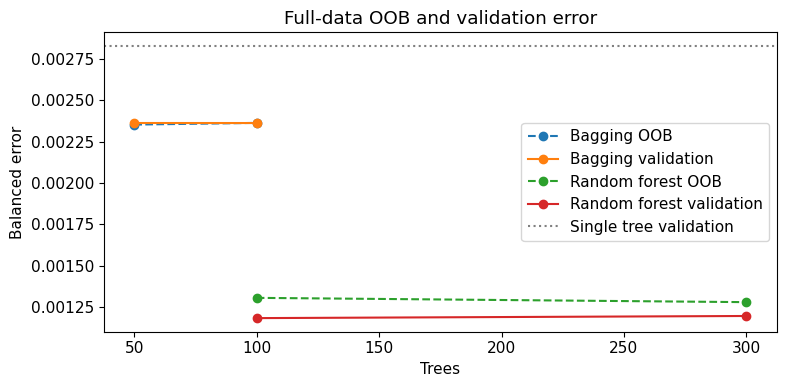

Review the generated report: ./Lab3/artifacts/runs/dfd699ed631cec5e90e1deb652a1c3952c3f400a5263268db8eb5a9439c87319/deadline/f947ccc912146802fbae/Lab3_Report_DRAFT.pdf
Evidence and appendix: ./Lab3/artifacts/runs/dfd699ed631cec5e90e1deb652a1c3952c3f400a5263268db8eb5a9439c87319/deadline/f947ccc912146802fbae


In [27]:
# Purpose: Export experimental evidence, settings, and comparison figures for the report.
# Explain: Exports document the recorded run; they do not complete omitted full-data searches.

from pathlib import Path
import shutil

appendix = {
    "seed": RANDOM_SEED, "original_split_configuration": split_configuration, "original_split_rows": {p: len(ids) for p, ids in partition_row_ids.items()},
    "software_versions": software_versions.to_dict(), "complete_feature_names": complete_feature_names,
    "numerical_features": numerical_features, "deadline_protocol": DEADLINE_PROTOCOL,
    "selected_xgb_provenance": selected_xgb_metadata,
    "selected_binary_settings": {name: model.get_params(deep=False) for name, model in selected_models.items()},
    "limitations": ["Original full-data 24-case XGBoost search not completed; reduced six-case sample search used.",
        "Selected binary XGBoost may use fewer training observations than the other families.",
        "Multiclass experiments use fixed training/validation samples and wall/round limits; actual stopped counts are reported.",
        "Port permutation importance is grouped; 5,000 validation rows and two repeats used.",
        "Fresh-fit cost measurements are 2,000-row proxies, not measured full-data fit times.",
        "Lab 3 logistic baseline does not exactly reproduce Lab 2's recorded rounded results."],
}
(DEADLINE_DIRECTORY / "appendix.json").write_text(json.dumps(appendix, indent=2, default=str))
multiclass_counts.to_csv(DEADLINE_DIRECTORY / "original_multiclass_counts.csv")
for name in ["baseline_validation_results.csv", "bagging_validation_results.csv", "rf_validation_results.csv", "gb_validation_results.csv"]:
    if (RUN_DIRECTORY / name).exists():
        shutil.copy2(RUN_DIRECTORY / name, DEADLINE_DIRECTORY / name)
# Save the completed full-data Part 2 comparison and OOB/validation plot.
metric_columns = ["balanced_accuracy", "attack_precision", "attack_recall", "attack_f1", "log_loss"]
part2_table = pd.DataFrame({
    "Decision tree": baseline_validation_results.loc["Decision tree", metric_columns],
    "Bagging": bagging_results.loc[bagging_model.n_estimators, metric_columns],
    "Random forest": rf_results.loc[selected_rf_key, metric_columns],
}).T
part2_table.to_csv(DEADLINE_DIRECTORY / "part2_validation_comparison.csv")
rf_curve = rf_results.xs(selected_rf_key[:2], level=("mtry", "min_samples_leaf")).sort_index()
fig, ax = plt.subplots(figsize=(8, 4))
for label, table in [("Bagging", bagging_results), ("Random forest", rf_curve)]:
    ax.plot(table.index, table["oob_balanced_error"], marker="o", linestyle="--", label=label + " OOB")
    ax.plot(table.index, table["validation_balanced_error"], marker="o", label=label + " validation")
ax.axhline(1 - baseline_validation_results.loc["Decision tree", "balanced_accuracy"], linestyle=":", color="gray", label="Single tree validation")
ax.set(xlabel="Trees", ylabel="Balanced error", title="Full-data OOB and validation error")
ax.legend()
fig.tight_layout()
fig.savefig(DEADLINE_DIRECTORY / "oob_validation_error.png", dpi=160)
plt.show()
for curve_path in RUN_DIRECTORY.glob("gb_curve_*.csv"):
    shutil.copy2(curve_path, DEADLINE_DIRECTORY / curve_path.name)
# Produce the report only once every required results table exists.
from build_deadline_report import build_report
report_path = build_report(DEADLINE_DIRECTORY)
print("Review the generated report:", report_path.resolve())
print("Evidence and appendix:", DEADLINE_DIRECTORY.resolve())
